# ADAR — Adaptive Deep Architecture Routing with a System-One head (Laya)

This notebook trains and evaluates everything for the ADAR project on **Kaggle GPU T4 ×2**:

| Stage | What it produces |
|---|---|
| Syllabus experts | TextCNN, Bi-RNN, Bi-LSTM, Bi-GRU (3-fold, out-of-fold predictions) |
| scikit-learn baselines | Naive Bayes, Logistic Regression, Linear SVM, Random Forest, MLPClassifier on TF-IDF |
| Laya embeddings | frozen `convaiinnovations/laya` encoder, cached in shards on both GPUs |
| Laya baselines | Laya zero-shot (typed choice), Laya + Logistic Regression probe, stacking baseline |
| **ADAR head** | 3 seeds + 3 ablations, temperature-scaled, publishable safetensors |
| Router | cascade (cheap experts first, Laya only when needed): threshold + REINFORCE policy |
| Report | comparison tables, QC gates with bootstrap CIs, reliability / latency / risk-coverage plots |
| typed-decisions | System One leaderboard evaluation of Laya checkpoints + ADAR-Cal |

### How to run
1. **Settings → Accelerator: GPU T4 ×2**, **Internet: On**.
2. (Optional, to upload the trained heads) **Add-ons → Secrets → `HF_TOKEN`** and set `HF_REPO_PREFIX` below.
3. **Save Version → Save & Run All (Commit)**. The run takes roughly 1.5–3 hours; outputs land in
   `/kaggle/working/adar_outputs.zip` and `/kaggle/working/adar_run/`.

### Saving progress & recovering from failures
* Every stage writes a checkpoint; expert and head training checkpoint **every epoch**, embeddings every shard.
* Re-running a cell skips finished work. A failing stage is logged to `adar_run/errors.log` and the
  run continues with independent stages (stages that depend on it are marked *blocked*).
* If a session dies or times out: open the notebook, **Add Input → Your Work → this notebook's last
  version** (its output), then run all again — the previous `adar_run/` is restored automatically and
  only unfinished stages run.

> **Executed run.** Outputs of the full Kaggle run (kernel `harshavardhan88/adar-system-one`, GPU T4 ×2, 63 minutes, 19/19 stages done). Text outputs are the kernel's own log (`results/kaggle_run/kernel.log`); tables and figures are the files the run wrote (`results/kaggle_run/`). Live version: https://www.kaggle.com/code/harshavardhan88/adar-system-one


In [1]:
import os, subprocess, sys, shutil
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout if shutil.which("nvidia-smi")
      else "no GPU visible - set Accelerator to GPU T4 x2 for the full run")
print("disk free (GB):", shutil.disk_usage("/kaggle/working" if os.path.exists("/kaggle/working") else ".").free / 1e9)
# laya = the open-source System One model (Apache-2.0); datasets = Hugging Face datasets
!pip install -q "laya>=0.3.23" datasets

GPU 0: Tesla T4 (UUID: GPU-a9ae2d78-c5d8-9e06-4b9e-d30ad29fcbc5)
GPU 1: Tesla T4 (UUID: GPU-e9d43f23-0391-6560-b0ab-c038274a453a)

disk free (GB): 20.940259328


## 1. The `adar` package
These cells write the project source (the same files as the GitHub repo).

In [2]:
os.makedirs('adar', exist_ok=True)

In [3]:
%%writefile adar/__init__.py
"""ADAR: Adaptive Deep Architecture Routing with a System-One decision head.

Modules
-------
utils      logging, seeding, atomic saves, retries, OOM back-off
runstate   resumable stage manager (Kaggle-safe checkpoint/restore)
data       dataset loading + label descriptions + stacking folds
metrics    accuracy / macro-F1 / NLL / Brier / ECE / temperature scaling
experts    syllabus experts: TextCNN, RNN, LSTM, GRU (train/resume/predict)
baselines  scikit-learn baselines on TF-IDF and on Laya embeddings
encoder    frozen Laya encoder (or a HF stand-in) with sharded multi-GPU caching
head       the ADAR System-One head (model, training, save/load)
router     cascade router (threshold + REINFORCE policy) and cost curves
laya_tasks Laya zero-shot baseline + typed-decisions leaderboard evaluation
report     comparison tables, plots, model card, output bundle
pipeline   stage functions the notebook calls
"""

__version__ = "0.1.0"

Writing adar/__init__.py


In [4]:
%%writefile adar/utils.py
import functools
import json
import logging
import os
import random
import shutil
import sys
import tempfile
import time
from contextlib import contextmanager

import numpy as np

LOG = logging.getLogger("adar")


def setup_logging(log_path=None, level=logging.INFO):
    LOG.setLevel(level)
    LOG.handlers.clear()
    fmt = logging.Formatter("%(asctime)s %(levelname)s %(message)s", "%H:%M:%S")
    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    LOG.addHandler(sh)
    if log_path:
        os.makedirs(os.path.dirname(log_path), exist_ok=True)
        fh = logging.FileHandler(log_path)
        fh.setFormatter(fmt)
        LOG.addHandler(fh)
    LOG.propagate = False
    return LOG


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def atomic_write_bytes(path, data):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=os.path.dirname(path) or ".", suffix=".tmp")
    with os.fdopen(fd, "wb") as f:
        f.write(data)
    os.chmod(tmp, 0o644)  # mkstemp creates 0600 files; outputs are meant to be shared
    os.replace(tmp, path)


def save_json(path, obj):
    atomic_write_bytes(path, json.dumps(obj, indent=2, default=_json_default).encode())


def load_json(path, default=None):
    if not os.path.exists(path):
        return default
    with open(path) as f:
        return json.load(f)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def save_npz(path, **arrays):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=os.path.dirname(path) or ".", suffix=".npz")
    os.close(fd)
    np.savez(tmp, **arrays)
    os.chmod(tmp, 0o644)
    os.replace(tmp, path)


def torch_save(obj, path):
    import torch
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=os.path.dirname(path) or ".", suffix=".pt")
    os.close(fd)
    torch.save(obj, tmp)
    os.chmod(tmp, 0o644)
    os.replace(tmp, path)


def retry(times=4, base_delay=2.0, exceptions=(Exception,)):
    """Retry with exponential back-off (2s, 4s, 8s, ...) - for flaky downloads."""
    def deco(fn):
        @functools.wraps(fn)
        def wrapped(*a, **kw):
            for attempt in range(times + 1):
                try:
                    return fn(*a, **kw)
                except exceptions as e:  # noqa: PERF203
                    if attempt == times:
                        raise
                    delay = base_delay * (2 ** attempt)
                    LOG.warning("%s failed (%s: %s); retry %d/%d in %.0fs",
                                fn.__name__, type(e).__name__, e, attempt + 1, times, delay)
                    time.sleep(delay)
        return wrapped
    return deco


def is_oom(err):
    msg = str(err).lower()
    return "out of memory" in msg or "cuda error: out of memory" in msg or type(err).__name__ == "OutOfMemoryError"


def run_with_oom_backoff(fn, batch_size, min_batch=1, what="step"):
    """Call fn(batch_size); on CUDA OOM free memory, halve the batch and try again."""
    import torch
    bs = batch_size
    while True:
        try:
            return fn(bs), bs
        except RuntimeError as e:
            if not is_oom(e) or bs <= min_batch:
                raise
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            bs = max(min_batch, bs // 2)
            LOG.warning("OOM during %s; retrying with batch_size=%d", what, bs)


@contextmanager
def timer(name, sink=None):
    t0 = time.time()
    yield
    dt = time.time() - t0
    LOG.info("%s took %.1fs", name, dt)
    if sink is not None:
        sink[name] = dt


def copytree_merge(src, dst):
    """Copy src into dst, keeping files that already exist in dst."""
    for root, _, files in os.walk(src):
        rel = os.path.relpath(root, src)
        out = os.path.join(dst, rel)
        os.makedirs(out, exist_ok=True)
        for f in files:
            target = os.path.join(out, f)
            if not os.path.exists(target):
                shutil.copy2(os.path.join(root, f), target)


def device_list():
    import torch
    if torch.cuda.is_available():
        return [torch.device(f"cuda:{i}") for i in range(torch.cuda.device_count())]
    return [torch.device("cpu")]


def count_params(module):
    return int(sum(p.numel() for p in module.parameters()))

Writing adar/utils.py


In [5]:
%%writefile adar/runstate.py
"""Resumable stage manager.

Every stage writes a `done` record into `<run_dir>/state.json` when it finishes, so re-running the
notebook (or a fresh Kaggle session restored from a previous version's output) skips finished
work. A failing stage records its traceback and, with `continue_on_error`, lets independent
stages keep running; stages that depend on it are skipped instead of crashing later.
"""
import glob
import os
import time
import traceback

from .utils import LOG, copytree_merge, load_json, save_json


class StageFailed(RuntimeError):
    pass


class RunState:
    def __init__(self, run_dir, continue_on_error=True, time_budget_h=None):
        self.run_dir = run_dir
        os.makedirs(run_dir, exist_ok=True)
        self.path = os.path.join(run_dir, "state.json")
        self.state = load_json(self.path, {"stages": {}})
        self.continue_on_error = continue_on_error
        self.t_start = time.time()
        self.time_budget_s = None if time_budget_h is None else time_budget_h * 3600

    # ---- restore ---------------------------------------------------------------------------
    @staticmethod
    def restore_from_inputs(run_dir, search_glob="/kaggle/input/*/**/adar_run"):
        """Copy a previous run (attached as a Kaggle input dataset / notebook output) into run_dir.

        Kaggle wipes /kaggle/working between sessions. Attach the previous version's output as an
        input and this picks up all finished stages, cached embeddings and checkpoints.
        """
        candidates = [p for p in glob.glob(search_glob, recursive=True)
                      if os.path.isfile(os.path.join(p, "state.json")) and os.path.abspath(p) != os.path.abspath(run_dir)]
        if not candidates:
            return None
        src = max(candidates, key=lambda p: os.path.getmtime(os.path.join(p, "state.json")))
        LOG.info("Restoring previous run from %s", src)
        copytree_merge(src, run_dir)
        return src

    # ---- bookkeeping -----------------------------------------------------------------------
    def _save(self):
        save_json(self.path, self.state)

    def status(self, name):
        return self.state["stages"].get(name, {}).get("status")

    def done(self, name):
        return self.status(name) == "done"

    def out_of_time(self, margin_s=900):
        if self.time_budget_s is None:
            return False
        return time.time() - self.t_start > self.time_budget_s - margin_s

    def reset(self, name):
        self.state["stages"].pop(name, None)
        self._save()

    def run(self, stage, fn, deps=(), force=False, **kwargs):
        """Run fn(**kwargs) as stage `stage` unless already done. Returns fn's result or None."""
        if self.done(stage) and not force:
            LOG.info("[skip] %s already done", stage)
            return self.state["stages"][stage].get("result")
        missing = [d for d in deps if not self.done(d)]
        if missing:
            msg = f"stage {stage} skipped: dependencies not done: {missing}"
            LOG.warning(msg)
            self.state["stages"][stage] = {"status": "blocked", "reason": msg}
            self._save()
            if not self.continue_on_error:
                raise StageFailed(msg)
            return None
        if self.out_of_time():
            LOG.warning("time budget nearly used; not starting %s (re-run to resume)", stage)
            return None
        LOG.info("[run ] %s", stage)
        t0 = time.time()
        self.state["stages"][stage] = {"status": "running", "started": t0}
        self._save()
        try:
            result = fn(**kwargs)
        except KeyboardInterrupt:
            self.state["stages"][stage] = {"status": "interrupted"}
            self._save()
            raise
        except Exception as e:  # noqa: BLE001
            tb = traceback.format_exc()
            LOG.error("stage %s FAILED: %s\n%s", stage, e, tb)
            self.state["stages"][stage] = {"status": "failed", "error": repr(e), "traceback": tb[-4000:]}
            self._save()
            with open(os.path.join(self.run_dir, "errors.log"), "a") as f:
                f.write(f"\n==== {stage} @ {time.ctime()} ====\n{tb}\n")
            if not self.continue_on_error:
                raise
            return None
        rec = {"status": "done", "seconds": round(time.time() - t0, 1)}
        if isinstance(result, (dict, list, str, int, float)) or result is None:
            rec["result"] = result
        self.state["stages"][stage] = rec
        self._save()
        LOG.info("[done] %s (%.1fs)", stage, rec["seconds"])
        return result

    def summary(self):
        rows = []
        for k, v in self.state["stages"].items():
            rows.append(f"{v.get('status', '?'):>11}  {k}  {v.get('seconds', '')}")
        return "\n".join(rows)

Writing adar/runstate.py


In [6]:
%%writefile adar/data.py
"""Datasets, label descriptions and stacking folds.

Each dataset becomes a `TaskData` with a train pool (split into K folds so every expert's
predictions on train are out-of-fold), a validation split (early stopping, temperature scaling,
router thresholds) and the official test split (touched only for final reporting).
"""
import csv
import io
import os
from dataclasses import dataclass, field

import numpy as np

from .utils import LOG, retry

# Option descriptions are what the System-One head (and Laya) reads for each label.
TASKS = {
    "ag_news": {
        "hf": [("fancyzhx/ag_news", None), ("ag_news", None)],
        "labels": ["world", "sports", "business", "sci_tech"],
        "descriptions": {
            "world": "world news: international affairs, politics, governments, conflicts, diplomacy",
            "sports": "sports news: games, matches, teams, players, leagues, championships",
            "business": "business news: companies, markets, economy, earnings, stocks, trade",
            "sci_tech": "science and technology news: computers, internet, software, space, research",
        },
        "instruction": "Which news category does this article belong to?",
        "github_csv": "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{split}.csv",
    },
    "emotion": {
        "hf": [("dair-ai/emotion", "split"), ("dair-ai/emotion", None)],
        "labels": ["sadness", "joy", "love", "anger", "fear", "surprise"],
        "descriptions": {
            "sadness": "sadness: feeling sad, unhappy, lonely, hurt, hopeless or disappointed",
            "joy": "joy: feeling happy, glad, cheerful, pleased, content or excited",
            "love": "love: feeling loving, caring, affectionate, romantic or tender",
            "anger": "anger: feeling angry, annoyed, irritated, furious or resentful",
            "fear": "fear: feeling afraid, scared, anxious, nervous or worried",
            "surprise": "surprise: feeling surprised, amazed, shocked or astonished",
        },
        "instruction": "Which emotion does the writer express?",
    },
}


@dataclass
class TaskData:
    name: str
    labels: list
    descriptions: dict
    instruction: str
    x_train: list
    y_train: np.ndarray
    x_val: list
    y_val: np.ndarray
    x_test: list
    y_test: np.ndarray
    folds: np.ndarray = field(default=None)

    @property
    def n_classes(self):
        return len(self.labels)

    def option_texts(self):
        return [self.descriptions[l] for l in self.labels]

    def split(self, name):
        return {"train": (self.x_train, self.y_train), "val": (self.x_val, self.y_val),
                "test": (self.x_test, self.y_test)}[name]

    def fingerprint(self):
        """Hash of every split's texts+labels. Cached embeddings/predictions are only reused when it
        matches, so a session that loaded the data from a different source can never silently
        mix rows."""
        import hashlib
        h = hashlib.sha256()
        for xs, ys in (self.split("train"), self.split("val"), self.split("test")):
            for x, y in zip(xs, ys.tolist()):
                h.update(x.encode("utf-8", "ignore"))
                h.update(str(y).encode())
            h.update(b"|")
        return h.hexdigest()[:16]

    def summary(self):
        return (f"{self.name}: train={len(self.x_train)} val={len(self.x_val)} test={len(self.x_test)} "
                f"classes={self.n_classes} folds={len(np.unique(self.folds))}")


@retry(times=3)
def _hf_load(path, config):
    from datasets import load_dataset
    return load_dataset(path, config) if config else load_dataset(path)


def _from_hf(spec):
    last = None
    for path, config in spec["hf"]:
        try:
            ds = _hf_load(path, config)
            out = {}
            for split in ds:
                out[split] = (list(ds[split]["text"]), np.asarray(ds[split]["label"], dtype=np.int64))
            LOG.info("loaded %s from Hugging Face (%s)", path, ", ".join(f"{k}={len(v[0])}" for k, v in out.items()))
            return out
        except Exception as e:  # noqa: BLE001
            last = e
            LOG.warning("HF load %s failed: %s", path, e)
    raise RuntimeError(f"could not load from Hugging Face: {last}")


def _ag_news_rows(text_iter):
    xs, ys = [], []
    for row in csv.reader(text_iter):
        if len(row) < 3:
            continue
        ys.append(int(row[0]) - 1)  # CSV labels are 1..4 in the same order as the HF dataset
        xs.append((row[1] + " " + row[2]).replace("\\", " ").strip())
    return xs, np.asarray(ys, dtype=np.int64)


@retry(times=3)
def _download(url):
    import urllib.request
    with urllib.request.urlopen(url, timeout=120) as r:
        return r.read().decode("utf-8")


def _ag_news_fallback(spec, local_dir=None):
    out = {}
    for split in ("train", "test"):
        if local_dir and os.path.exists(os.path.join(local_dir, f"{split}.csv")):
            with open(os.path.join(local_dir, f"{split}.csv"), newline="", encoding="utf-8") as f:
                out[split] = _ag_news_rows(f)
        else:
            out[split] = _ag_news_rows(io.StringIO(_download(spec["github_csv"].format(split=split))))
    LOG.info("loaded ag_news from CSV (train=%d test=%d)", len(out["train"][0]), len(out["test"][0]))
    return out


def _stratified_take(y, n, rng):
    """Indices of a class-stratified random subset of size ~n (all rows when n is None/too big)."""
    idx = np.arange(len(y))
    if n is None or n >= len(y):
        return rng.permutation(idx)
    take = []
    for c in np.unique(y):
        ci = idx[y == c]
        k = max(1, int(round(n * len(ci) / len(y))))
        take.append(rng.choice(ci, size=min(k, len(ci)), replace=False))
    return rng.permutation(np.concatenate(take))


def load_task(name, n_train=None, n_val=None, n_test=None, n_folds=3, seed=0, local_dir=None, source="auto"):
    """Load a task and build the train pool / folds / val / test splits.

    n_train / n_val / n_test cap the split sizes (stratified); None keeps everything.
    When the dataset has no official validation split, n_val rows are held out of train.
    """
    spec = TASKS[name]
    raw = None
    if source in ("auto", "hf") and not local_dir:
        try:
            raw = _from_hf(spec)
        except Exception as e:  # noqa: BLE001
            if source == "hf":
                raise
            LOG.warning("falling back from HF for %s: %s", name, e)
    if raw is None:
        if name != "ag_news":
            raise RuntimeError(f"{name}: no fallback source; enable internet / HF access")
        raw = _ag_news_fallback(spec, local_dir)

    rng = np.random.RandomState(seed)
    x_tr_all, y_tr_all = raw["train"]
    if "validation" in raw:
        x_va_all, y_va_all = raw["validation"]
        vi = _stratified_take(y_va_all, n_val, rng)
        x_val, y_val = [x_va_all[i] for i in vi], y_va_all[vi]
        pool = np.arange(len(y_tr_all))
    else:
        n_val = n_val or max(1000, len(y_tr_all) // 20)
        vi = _stratified_take(y_tr_all, n_val, rng)
        x_val, y_val = [x_tr_all[i] for i in vi], y_tr_all[vi]
        pool = np.setdiff1d(np.arange(len(y_tr_all)), vi)
    ti = pool[_stratified_take(y_tr_all[pool], n_train, rng)]
    x_train, y_train = [x_tr_all[i] for i in ti], y_tr_all[ti]
    x_te_all, y_te_all = raw["test"]
    ei = np.sort(_stratified_take(y_te_all, n_test, rng))
    x_test, y_test = [x_te_all[i] for i in ei], y_te_all[ei]

    # stratified fold ids for out-of-fold expert predictions
    folds = np.zeros(len(y_train), dtype=np.int64)
    for c in np.unique(y_train):
        ci = np.where(y_train == c)[0]
        ci = ci[rng.permutation(len(ci))]
        folds[ci] = np.arange(len(ci)) % n_folds

    td = TaskData(name, list(spec["labels"]), dict(spec["descriptions"]), spec["instruction"],
                  x_train, y_train, x_val, y_val, x_test, y_test, folds)
    LOG.info(td.summary())
    return td

Writing adar/data.py


In [7]:
%%writefile adar/metrics.py
"""Metrics and calibration. All probabilistic outputs are (N, K) arrays of probabilities."""
import numpy as np
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score

EPS = 1e-12


def to_logits(p):
    return np.log(np.clip(p, EPS, 1.0))


def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


def nll(p, y):
    return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], EPS, 1.0))))


def brier(p, y):
    onehot = np.eye(p.shape[1])[y]
    return float(np.mean(np.sum((p - onehot) ** 2, axis=1)))


def ece(p, y, bins=15):
    conf = p.max(1)
    correct = (p.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for i in range(bins):
        sel = (conf > edges[i]) & (conf <= edges[i + 1]) if i else (conf >= 0) & (conf <= edges[1])
        if sel.any():
            e += sel.mean() * abs(conf[sel].mean() - correct[sel].mean())
    return float(e)


def reliability_bins(p, y, bins=10):
    conf = p.max(1)
    correct = (p.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    rows = []
    for i in range(bins):
        sel = (conf > edges[i]) & (conf <= edges[i + 1]) if i else (conf <= edges[1])
        if sel.any():
            rows.append((float((edges[i] + edges[i + 1]) / 2), float(conf[sel].mean()),
                         float(correct[sel].mean()), int(sel.sum())))
    return rows


def risk_coverage(p, y, points=50):
    """Accuracy on the most-confident fraction `coverage` of inputs (selective classification)."""
    order = np.argsort(-p.max(1))
    correct = (p.argmax(1) == y)[order].astype(float)
    cum = np.cumsum(correct) / np.arange(1, len(y) + 1)
    covs = np.linspace(1.0 / points, 1.0, points)
    return [(float(c), float(cum[max(0, int(round(c * len(y))) - 1)])) for c in covs]


def aurc(p, y):
    """Area under the risk-coverage curve (lower is better)."""
    order = np.argsort(-p.max(1))
    err = (p.argmax(1) != y)[order].astype(float)
    return float(np.mean(np.cumsum(err) / np.arange(1, len(y) + 1)))


def fit_temperature(logits, y, lo=0.05, hi=20.0):
    """Single temperature T minimising validation NLL of softmax(logits / T)."""
    def f(log_t):
        return nll(softmax(logits / np.exp(log_t)), y)
    r = minimize_scalar(f, bounds=(np.log(lo), np.log(hi)), method="bounded", options={"xatol": 1e-4})
    return float(np.exp(r.x))


def apply_temperature(p_or_logits, t, is_prob=True):
    z = to_logits(p_or_logits) if is_prob else p_or_logits
    return softmax(z / t)


def all_metrics(p, y):
    pred = p.argmax(1)
    return {
        "accuracy": float((pred == y).mean()),
        "macro_f1": float(f1_score(y, pred, average="macro")),
        "nll": nll(p, y),
        "brier": brier(p, y),
        "ece": ece(p, y),
        "aurc": aurc(p, y),
    }


def bootstrap_ci(p, y, metric="accuracy", n=1000, seed=0):
    rng = np.random.RandomState(seed)
    pred = p.argmax(1)
    vals = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if metric == "accuracy":
            vals.append((pred[i] == y[i]).mean())
        else:
            vals.append(all_metrics(p[i], y[i])[metric])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def paired_bootstrap_delta(p_a, p_b, y, n=2000, seed=0):
    """95% CI of accuracy(a) - accuracy(b) on the same examples."""
    rng = np.random.RandomState(seed)
    ca = (p_a.argmax(1) == y).astype(float)
    cb = (p_b.argmax(1) == y).astype(float)
    d = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        d.append(ca[i].mean() - cb[i].mean())
    return float(np.mean(ca - cb)), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

Writing adar/metrics.py


In [8]:
%%writefile adar/experts.py
"""Syllabus experts: TextCNN (Unit I/II), vanilla RNN, LSTM, GRU (Unit III).

Each expert is trained K times (one per stacking fold) so that its predictions on the training
pool are out-of-fold - the ADAR head and router never see an expert's predictions on data that
expert was trained on. Val/test predictions are the average over the K fold models.
Training checkpoints every epoch and resumes after an interruption.
"""
import os
import re
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .utils import LOG, count_params, load_json, save_json, save_npz, seed_everything, torch_save

_TOKEN = re.compile(r"[a-z0-9']+")


def tokenize(text):
    return _TOKEN.findall(text.lower())


class Vocab:
    PAD, UNK = 0, 1

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    @classmethod
    def build(cls, texts, max_size=30000, min_freq=2):
        c = Counter()
        for t in texts:
            c.update(tokenize(t))
        words = [w for w, n in c.most_common(max_size) if n >= min_freq]
        return cls(["<pad>", "<unk>"] + words)

    def encode(self, texts, max_len):
        ids = np.zeros((len(texts), max_len), dtype=np.int64)
        lens = np.ones(len(texts), dtype=np.int64)
        for i, t in enumerate(texts):
            toks = [self.stoi.get(w, self.UNK) for w in tokenize(t)][:max_len] or [self.UNK]
            ids[i, :len(toks)] = toks
            lens[i] = len(toks)
        return ids, lens

    def __len__(self):
        return len(self.itos)


class TextCNN(nn.Module):
    """Kim (2014) CNN for sentences, with BatchNorm after each convolution."""

    def __init__(self, vocab_size, n_classes, emb=128, channels=128, kernels=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb, channels, k, padding=k // 2) for k in kernels])
        self.bns = nn.ModuleList([nn.BatchNorm1d(channels) for _ in kernels])
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(channels * len(kernels), n_classes)

    def forward(self, ids, lens):
        mask = (ids != 0).unsqueeze(1)  # B,1,T
        x = self.emb(ids).transpose(1, 2)  # B,E,T
        feats = []
        for conv, bn in zip(self.convs, self.bns):
            h = F.relu(bn(conv(x)))[:, :, : ids.size(1)]
            h = h.masked_fill(~mask, -1e4)
            feats.append(h.max(dim=2).values)
        return self.out(self.drop(torch.cat(feats, 1)))


class RNNClassifier(nn.Module):
    """Bidirectional RNN / LSTM / GRU with mean+max pooling over valid time steps."""

    CELLS = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}

    def __init__(self, cell, vocab_size, n_classes, emb=128, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        kw = {"nonlinearity": "tanh"} if cell == "rnn" else {}
        self.rnn = self.CELLS[cell](emb, hidden, batch_first=True, bidirectional=True, **kw)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(4 * hidden, n_classes)

    def forward(self, ids, lens):
        x = self.drop(self.emb(ids))
        packed = nn.utils.rnn.pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.rnn(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        mask = (torch.arange(ids.size(1), device=ids.device)[None, :] < lens[:, None]).unsqueeze(-1)
        mean = (h * mask).sum(1) / lens[:, None].clamp(min=1)
        mx = h.masked_fill(~mask, -1e4).max(1).values
        return self.out(self.drop(torch.cat([mean, mx], 1)))


EXPERT_KINDS = ("textcnn", "rnn", "lstm", "gru")
EXPERT_UNITS = {"textcnn": "Unit I-II (CNN)", "rnn": "Unit III (RNN)", "lstm": "Unit III (LSTM)",
                "gru": "Unit III (GRU)"}


def build_expert(kind, vocab_size, n_classes):
    if kind == "textcnn":
        return TextCNN(vocab_size, n_classes)
    return RNNClassifier(kind, vocab_size, n_classes)


@torch.no_grad()
def predict_proba(model, ids, lens, device, batch_size=1024):
    model.eval()
    out = []
    for i in range(0, len(ids), batch_size):
        b_ids = torch.as_tensor(ids[i:i + batch_size], device=device)
        b_len = torch.as_tensor(lens[i:i + batch_size], device=device)
        out.append(torch.softmax(model(b_ids, b_len).float(), -1).cpu().numpy())
    return np.concatenate(out)


def train_one(kind, ids, lens, y, val_ids, val_lens, y_val, n_classes, vocab_size, device, ckpt_path,
              epochs=5, batch_size=256, lr=2e-3, patience=2, seed=0):
    """Train one expert; resumes from ckpt_path. Returns the best (val-NLL) model."""
    seed_everything(seed)
    model = build_expert(kind, vocab_size, n_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    start, best, best_state, bad, hist = 0, float("inf"), None, 0, []
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        start, best, best_state, bad, hist = ck["epoch"], ck["best"], ck["best_state"], ck["bad"], ck["hist"]
        LOG.info("  resume %s from epoch %d (best val nll %.4f)", os.path.basename(ckpt_path), start, best)
        if ck.get("finished"):
            model.load_state_dict(best_state)
            return model, hist
    t_ids = torch.as_tensor(ids, device=device)
    t_lens = torch.as_tensor(lens, device=device)
    t_y = torch.as_tensor(y, device=device)
    for ep in range(start, epochs):
        model.train()
        perm = torch.randperm(len(y), device=device)
        tot, nb, t0 = 0.0, 0, time.time()
        for i in range(0, len(y), batch_size):
            b = perm[i:i + batch_size]
            if len(b) < 2:
                continue
            loss = F.cross_entropy(model(t_ids[b], t_lens[b]), t_y[b])
            if not torch.isfinite(loss):
                LOG.warning("  non-finite loss in %s epoch %d; skipping batch", kind, ep)
                opt.zero_grad(set_to_none=True)
                continue
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # guards against exploding gradients
            opt.step()
            tot, nb = tot + loss.item(), nb + 1
        pv = predict_proba(model, val_ids, val_lens, device)
        v_nll = float(-np.mean(np.log(np.clip(pv[np.arange(len(y_val)), y_val], 1e-12, 1))))
        v_acc = float((pv.argmax(1) == y_val).mean())
        hist.append({"epoch": ep + 1, "train_loss": tot / max(nb, 1), "val_nll": v_nll, "val_acc": v_acc,
                     "seconds": round(time.time() - t0, 1)})
        LOG.info("  %s ep%d loss=%.4f val_nll=%.4f val_acc=%.4f (%.0fs)", kind, ep + 1, tot / max(nb, 1),
                 v_nll, v_acc, time.time() - t0)
        if v_nll < best - 1e-4:
            best, bad = v_nll, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        stop = bad >= patience or ep + 1 == epochs
        torch_save({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": ep + 1, "best": best,
                    "best_state": best_state, "bad": bad, "hist": hist, "finished": stop}, ckpt_path)
        if stop:
            break
    model.load_state_dict(best_state)
    return model, hist


def measure_cpu_latency(model, ids, lens, n=64, threads=4):
    """Median per-sample latency (ms) at batch size 1 on CPU - the 'runs on a laptop' number."""
    import copy
    m = copy.deepcopy(model).cpu().eval()
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    times = []
    with torch.no_grad():
        for i in range(min(n, len(ids))):
            a = torch.as_tensor(ids[i:i + 1])
            b = torch.as_tensor(lens[i:i + 1])
            t0 = time.perf_counter()
            m(a, b)
            times.append((time.perf_counter() - t0) * 1000)
    torch.set_num_threads(old)
    return float(np.median(times[5:] if len(times) > 10 else times))


def run_experts(task, out_dir, device, kinds=EXPERT_KINDS, epochs=5, max_len=64, batch_size=256, seed=0):
    """Train every expert on every fold; write experts/<kind>.npz with oof/val/test probabilities."""
    os.makedirs(out_dir, exist_ok=True)
    vocab_path = os.path.join(out_dir, "vocab.json")
    if os.path.exists(vocab_path):
        vocab = Vocab(load_json(vocab_path))
    else:
        vocab = Vocab.build(task.x_train)
        save_json(vocab_path, vocab.itos)
    tr_ids, tr_lens = vocab.encode(task.x_train, max_len)
    va_ids, va_lens = vocab.encode(task.x_val, max_len)
    te_ids, te_lens = vocab.encode(task.x_test, max_len)
    n_folds = int(task.folds.max()) + 1
    summary = {}
    for kind in kinds:
        final = os.path.join(out_dir, f"{kind}.npz")
        if os.path.exists(final):
            LOG.info("expert %s already trained", kind)
            summary[kind] = load_json(os.path.join(out_dir, f"{kind}.json"))
            continue
        oof = np.zeros((len(task.y_train), task.n_classes), dtype=np.float32)
        val_p, test_p, hists, lat, params = [], [], [], None, None
        for f in range(n_folds):
            fold_npz = os.path.join(out_dir, f"{kind}_fold{f}.npz")
            tr = task.folds != f
            if os.path.exists(fold_npz):
                d = np.load(fold_npz)
                oof[~tr], fv, ft = d["oof"], d["val"], d["test"]
                meta = load_json(fold_npz.replace(".npz", ".json"))
                hists.append(meta["hist"])
                lat, params = meta["latency_ms"], meta["params"]
            else:
                model, hist = train_one(kind, tr_ids[tr], tr_lens[tr], task.y_train[tr], va_ids, va_lens, task.y_val,
                                        task.n_classes, len(vocab), device,
                                        os.path.join(out_dir, "ckpt", f"{kind}_fold{f}.pt"),
                                        epochs=epochs, batch_size=batch_size, seed=seed + f)
                oof[~tr] = predict_proba(model, tr_ids[~tr], tr_lens[~tr], device)
                fv = predict_proba(model, va_ids, va_lens, device)
                ft = predict_proba(model, te_ids, te_lens, device)
                lat = measure_cpu_latency(model, te_ids, te_lens)
                params = count_params(model)
                save_npz(fold_npz, oof=oof[~tr], val=fv, test=ft)
                save_json(fold_npz.replace(".npz", ".json"), {"hist": hist, "latency_ms": lat, "params": params})
                torch_save(model.state_dict(), os.path.join(out_dir, "weights", f"{kind}_fold{f}.pt"))
                hists.append(hist)
            val_p.append(fv)
            test_p.append(ft)
        val_m, test_m = np.mean(val_p, 0), np.mean(test_p, 0)
        save_npz(final, oof=oof, val=val_m, test=test_m)
        info = {"kind": kind, "params": params, "cpu_latency_ms": lat, "folds": n_folds, "history": hists,
                "oof_acc": float((oof.argmax(1) == task.y_train).mean()),
                "val_acc": float((val_m.argmax(1) == task.y_val).mean())}
        save_json(os.path.join(out_dir, f"{kind}.json"), info)
        summary[kind] = info
        LOG.info("expert %s: oof_acc=%.4f val_acc=%.4f params=%d cpu=%.2fms", kind, info["oof_acc"],
                 info["val_acc"], params, lat)
    return {k: {"oof_acc": v["oof_acc"], "val_acc": v["val_acc"]} for k, v in summary.items()}


def load_expert_probs(out_dir, kinds):
    d = {k: np.load(os.path.join(out_dir, f"{k}.npz")) for k in kinds}
    return ({k: d[k]["oof"] for k in kinds}, {k: d[k]["val"] for k in kinds}, {k: d[k]["test"] for k in kinds})

Writing adar/experts.py


In [9]:
%%writefile adar/baselines.py
"""scikit-learn baselines (the 'standard models' comparison).

TF-IDF features: Multinomial NB, Logistic Regression, Linear SVM (Platt-calibrated), Random Forest,
sklearn MLPClassifier. Embedding features: Logistic Regression on the frozen Laya encoder
(a linear probe - the strongest 'no new architecture' baseline).
"""
import os
import pickle
import time

import numpy as np
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from .utils import LOG, load_json, save_json, save_npz

TFIDF_MODELS = {
    "sk_naive_bayes": lambda: MultinomialNB(alpha=0.1),
    "sk_logreg": lambda: LogisticRegression(C=10.0, max_iter=2000),
    "sk_linear_svm": lambda: CalibratedClassifierCV(LinearSVC(C=0.5), cv=3, method="sigmoid"),
    "sk_random_forest": lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, min_samples_leaf=1, random_state=0),
    # MLP on all 200k TF-IDF columns is impractically slow (dense 200k x 256 weight updates);
    # it gets the 20k most informative columns (chi-squared), selected on its own training rows.
    "sk_mlp": lambda: make_pipeline(SelectKBest(chi2, k=20000),
                                    MLPClassifier(hidden_layer_sizes=(256,), early_stopping=True, max_iter=40,
                                                  n_iter_no_change=3, random_state=0, batch_size=256)),
}
# Random forest / sklearn-MLP are slow on 100k+ sparse rows; cap their training rows (reported).
ROW_CAP = {"sk_random_forest": 30000, "sk_mlp": 40000}


def _latency(fn, texts, n=50):
    times = []
    for t in texts[:n]:
        t0 = time.perf_counter()
        fn([t])
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


def run_tfidf_baselines(task, out_dir, models=tuple(TFIDF_MODELS), seed=0):
    os.makedirs(out_dir, exist_ok=True)
    vec_path = os.path.join(out_dir, "tfidf.pkl")
    if os.path.exists(vec_path):
        with open(vec_path, "rb") as f:
            vec = pickle.load(f)
    else:
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200000, sublinear_tf=True)
        vec.fit(task.x_train)
        with open(vec_path, "wb") as f:
            pickle.dump(vec, f)
    xtr, xva, xte = vec.transform(task.x_train), vec.transform(task.x_val), vec.transform(task.x_test)
    res = {}
    rng = np.random.RandomState(seed)
    for name in models:
        npz = os.path.join(out_dir, f"{name}.npz")
        if os.path.exists(npz):
            res[name] = load_json(npz.replace(".npz", ".json"))
            LOG.info("baseline %s already done", name)
            continue
        idx = np.arange(len(task.y_train))
        cap = ROW_CAP.get(name)
        if cap and len(idx) > cap:
            idx = np.sort(rng.choice(idx, cap, replace=False))
        t0 = time.time()
        clf = TFIDF_MODELS[name]()
        clf.fit(xtr[idx], task.y_train[idx])
        fit_s = time.time() - t0
        pv, pt = clf.predict_proba(xva), clf.predict_proba(xte)
        lat = _latency(lambda t: clf.predict_proba(vec.transform(t)), task.x_test)
        save_npz(npz, val=pv.astype(np.float32), test=pt.astype(np.float32))
        info = {"name": name, "train_rows": int(len(idx)), "fit_seconds": round(fit_s, 1), "cpu_latency_ms": lat,
                "val_acc": float((pv.argmax(1) == task.y_val).mean())}
        save_json(npz.replace(".npz", ".json"), info)
        res[name] = info
        LOG.info("baseline %s: val_acc=%.4f fit=%.0fs rows=%d", name, info["val_acc"], fit_s, len(idx))
    return {k: v["val_acc"] for k, v in res.items()}


def run_embedding_probe(task, emb, out_dir, name="laya_linear_probe"):
    """Logistic regression on frozen encoder embeddings, trained on the whole train pool."""
    npz = os.path.join(out_dir, f"{name}.npz")
    if os.path.exists(npz):
        return load_json(npz.replace(".npz", ".json"))
    scaler = StandardScaler().fit(emb["train"])
    t0 = time.time()
    clf = LogisticRegression(C=0.5, max_iter=3000)
    clf.fit(scaler.transform(emb["train"]), task.y_train)
    pv = clf.predict_proba(scaler.transform(emb["val"]))
    pt = clf.predict_proba(scaler.transform(emb["test"]))
    lat = _latency(lambda z: clf.predict_proba(scaler.transform(np.asarray(z))), list(emb["test"]))
    save_npz(npz, val=pv.astype(np.float32), test=pt.astype(np.float32))
    info = {"name": name, "fit_seconds": round(time.time() - t0, 1), "cpu_latency_ms_head_only": lat,
            "val_acc": float((pv.argmax(1) == task.y_val).mean())}
    save_json(npz.replace(".npz", ".json"), info)
    LOG.info("%s: val_acc=%.4f", name, info["val_acc"])
    return info

Writing adar/baselines.py


In [10]:
%%writefile adar/encoder.py
"""Frozen System-One encoder with sharded, resumable, multi-GPU embedding cache.

backend="laya": the encoder inside a Laya checkpoint (ModernBERT-large fine-tuned by RLCD),
                loaded with `laya.load`, exactly as `laya.shortlist.embed_fn_from_agent` uses it.
backend="hf"  : any Hugging Face encoder (used as a stand-in for local smoke tests).

Pooled representation = [mean over tokens ; first token]  ->  2 * hidden_size dims.
"""
import os
import queue
import threading
import time

import numpy as np
import torch

from .utils import LOG, is_oom, load_json, save_json


class FrozenEncoder:
    def __init__(self, backend, model_id, device, max_len=128, subfolder=None):
        self.backend, self.model_id, self.device, self.max_len = backend, model_id, torch.device(device), max_len
        if backend == "laya":
            import laya
            kw = {"subfolder": subfolder} if subfolder else {}
            self.agent = laya.load(model_id, device=str(self.device), **kw)
            if self.agent.device != self.device:  # laya falls back to CPU when the GPU is out of memory
                LOG.warning("laya loaded on %s instead of %s", self.agent.device, self.device)
                self.device = self.agent.device
            self.tok = self.agent.tok
            self.model = self.agent.model.encoder
        elif backend == "hf":
            from transformers import AutoModel, AutoTokenizer
            self.agent = None
            self.tok = AutoTokenizer.from_pretrained(model_id)
            self.model = AutoModel.from_pretrained(model_id).to(self.device)
        else:
            raise ValueError(backend)
        self.model.eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.hidden = int(self.model.config.hidden_size)
        self.dim = 2 * self.hidden

    def _tokenize(self, texts):
        return self.tok(list(texts), padding=True, truncation=True, max_length=self.max_len, return_tensors="pt")

    @torch.inference_mode()
    def _embed_batch(self, texts):
        enc = self._tokenize(texts)
        ids = enc["input_ids"].to(self.device)
        am = enc["attention_mask"].to(self.device)
        use_amp = self.device.type == "cuda"
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            h = self.model(input_ids=ids, attention_mask=am).last_hidden_state
        h = h.float()
        m = am.unsqueeze(-1).float()
        mean = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return torch.cat([mean, h[:, 0]], -1).cpu().numpy()

    def embed(self, texts, batch_size=64):
        """Embed texts (length-sorted batches to minimise padding; output in input order)."""
        texts = ["" if t is None else str(t) for t in texts]
        order = np.argsort([len(t) for t in texts])
        out = np.zeros((len(texts), self.dim), dtype=np.float32)
        i, bs = 0, batch_size
        while i < len(texts):
            idx = order[i:i + bs]
            try:
                out[idx] = self._embed_batch([texts[j] for j in idx])
                i += len(idx)
            except RuntimeError as e:
                if not is_oom(e) or bs == 1:
                    raise
                torch.cuda.empty_cache()
                bs = max(1, bs // 2)
                LOG.warning("encoder OOM on %s; batch_size -> %d", self.device, bs)
        return out

    def cpu_latency_ms(self, texts, n=20, threads=4, question=None):
        """Median batch-1 latency on CPU (loads a CPU copy for the measurement).

        Returns {"encoder": ms, "zero_shot": ms or None}; zero_shot times a full Laya typed
        decision (`agent.system_one`) when `question` is given and the backend is Laya."""
        old = torch.get_num_threads()
        torch.set_num_threads(threads)
        try:
            cpu = FrozenEncoder(self.backend, self.model_id, "cpu", self.max_len) if self.device.type != "cpu" else self

            def med(fn):
                times = []
                for t in texts[:n]:
                    t0 = time.perf_counter()
                    fn(t)
                    times.append((time.perf_counter() - t0) * 1000)
                return float(np.median(times[2:] if len(times) > 5 else times))

            out = {"encoder": med(lambda t: cpu._embed_batch([t])), "zero_shot": None}
            if question is not None and cpu.agent is not None:
                out["zero_shot"] = med(lambda t: cpu.agent.system_one(t, question))
            if cpu is not self:
                del cpu
            return out
        finally:
            torch.set_num_threads(old)


def _shard_path(cache_dir, split, i):
    return os.path.join(cache_dir, split, f"shard_{i:05d}.npy")


def cached_embed(encoders, texts, cache_dir, split, shard_size=4096, batch_size=64, meta=None):
    """Embed `texts` with resumable shards; work is spread over every encoder (one per GPU)."""
    os.makedirs(os.path.join(cache_dir, split), exist_ok=True)
    man_path = os.path.join(cache_dir, split, "manifest.json")
    man = load_json(man_path)
    want = {"n": len(texts), "shard_size": shard_size, **(meta or {})}
    if man is not None and man.get("spec") != want:
        raise RuntimeError(f"embedding cache {cache_dir}/{split} was built for different data/model: "
                           f"{man.get('spec')} != {want}. Delete it or change run_dir.")
    save_json(man_path, {"spec": want})
    n_shards = (len(texts) + shard_size - 1) // shard_size
    todo = [i for i in range(n_shards) if not os.path.exists(_shard_path(cache_dir, split, i))]
    if todo:
        LOG.info("embedding %s: %d/%d shards to do on %d device(s)", split, len(todo), n_shards, len(encoders))
        q = queue.Queue()
        for i in todo:
            q.put(i)
        errors = []
        t0 = time.time()

        def worker(enc):
            while not errors:
                try:
                    i = q.get_nowait()
                except queue.Empty:
                    return
                try:
                    emb = enc.embed(texts[i * shard_size:(i + 1) * shard_size], batch_size=batch_size)
                    p = _shard_path(cache_dir, split, i)
                    np.save(p + ".tmp.npy", emb.astype(np.float16))
                    os.replace(p + ".tmp.npy", p)
                    done = n_shards - q.qsize()
                    LOG.info("  %s shard %d done on %s (%d/%d, %.0fs)", split, i, enc.device, done, n_shards,
                             time.time() - t0)
                except Exception as e:  # noqa: BLE001
                    errors.append(e)
                    return

        threads = [threading.Thread(target=worker, args=(e,)) for e in encoders]
        for t in threads:
            t.start()
        for t in threads:
            t.join()
        if errors:
            raise errors[0]
    return np.concatenate([np.load(_shard_path(cache_dir, split, i)).astype(np.float32) for i in range(n_shards)])

Writing adar/encoder.py


In [11]:
%%writefile adar/head.py
"""The ADAR System-One head.

One decision = one short token sequence, in the spirit of Laya's typed decision head:

    [STATE]  the frozen System-One (Laya) embedding of the input
    [OPT_k]  one token per answer option, built from the encoder embedding of the option's
             *description* plus every expert's probability for that option
    [EXP_e]  one token per syllabus expert (TextCNN / RNN / LSTM / GRU) carrying how sure it is

A 2-layer transformer lets the tokens attend to each other (Unit III: attention). Outputs:

    choice   logits_k = scorer(OPT_k) + bilinear(STATE, OPT_k) + sum_e alpha_e(x) * log p_e,k
             (alpha = per-input expert routing weights: the "adaptive routing" in ADAR)
    noul     P(expert e is right) for every expert          -> which architecture to trust
    act      P(the head's own answer is right)              -> escalate / abstain gate

Training minimises strictly proper scoring rules (log score + Brier), the objective Laya's RLCD
rewards, then a single temperature is fitted on validation data.
"""
import json
import math
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .metrics import fit_temperature
from .utils import LOG, count_params, save_json, seed_everything, torch_save


def expert_summary(p):
    """Per-expert features: max prob, top1-top2 margin, normalised entropy, agreement with others."""
    B, E, K = p.shape
    top2 = p.topk(min(2, K), -1).values
    mx = top2[..., 0]
    margin = top2[..., 0] - (top2[..., 1] if K > 1 else 0)
    ent = -(p * p.clamp_min(1e-9).log()).sum(-1) / math.log(K)
    am = p.argmax(-1)
    agree = (am[:, :, None] == am[:, None, :]).float().sum(-1).sub(1) / max(E - 1, 1)
    return torch.stack([mx, margin, ent, agree], -1)


class ADARHead(nn.Module):
    def __init__(self, state_dim, opt_dim, n_experts, d=256, layers=2, heads=4, dropout=0.1,
                 use_state=True, use_experts=True, use_transformer=True):
        super().__init__()
        self.cfg = dict(state_dim=state_dim, opt_dim=opt_dim, n_experts=n_experts, d=d, layers=layers, heads=heads,
                        dropout=dropout, use_state=use_state, use_experts=use_experts, use_transformer=use_transformer)
        self.use_state, self.use_experts, self.use_transformer = use_state, use_experts and n_experts > 0, use_transformer
        E = max(n_experts, 1)
        self.state_proj = nn.Sequential(nn.LayerNorm(state_dim), nn.Dropout(dropout), nn.Linear(state_dim, d))
        self.state_null = nn.Parameter(torch.zeros(d))
        self.opt_proj = nn.Sequential(nn.LayerNorm(opt_dim), nn.Linear(opt_dim, d))
        self.opt_evidence = nn.Linear(2 * E, d)
        self.exp_feat = nn.Linear(4, d)
        self.exp_id = nn.Embedding(E, d)
        self.type_emb = nn.Embedding(3, d)
        if use_transformer:
            layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout, batch_first=True, norm_first=True)
            self.mixer = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.scorer = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, 1))
        self.bil_s = nn.Linear(d, d, bias=False)
        self.bil_o = nn.Linear(d, d, bias=False)
        self.gate = nn.Linear(d, E)
        nn.init.zeros_(self.gate.weight)
        nn.init.constant_(self.gate.bias, math.log(math.e - 1))  # softplus(bias) = 1 -> plain log-linear pool at init
        self.expert_noul = nn.Linear(d, 1)
        self.act_head = nn.Sequential(nn.Linear(d + 3, 64), nn.GELU(), nn.Linear(64, 1))
        self.register_buffer("temperature", torch.ones(()))

    def forward(self, z, opts, p_exp=None, exp_mask=None):
        """z: (B, Ds) state embeddings; opts: (K, Do) option embeddings; p_exp: (B, E, K) expert probs;
        exp_mask: (B, E) 1 = expert available (used for expert-dropout and missing experts)."""
        B, K = z.size(0), opts.size(0)
        s0 = self.state_proj(z) if self.use_state else self.state_null.expand(B, -1)
        o0 = self.opt_proj(opts).unsqueeze(0).expand(B, -1, -1)  # B,K,d
        tokens = [s0.unsqueeze(1) + self.type_emb.weight[0]]
        o = o0 + self.type_emb.weight[1]
        if self.use_experts:
            E = p_exp.size(1)
            m = torch.ones(B, E, device=z.device) if exp_mask is None else exp_mask.float()
            p_eff = p_exp * m[..., None] + (1 - m[..., None]) / K  # missing expert -> uniform evidence
            logp = p_eff.clamp_min(1e-6).log()
            ev = torch.cat([logp, p_eff], 1).transpose(1, 2)  # B,K,2E
            o = o + self.opt_evidence(ev)
            ex = self.exp_feat(expert_summary(p_eff) * m[..., None]) + self.exp_id.weight[:E] + self.type_emb.weight[2]
            tokens += [o, ex]
        else:
            tokens += [o]
        h = torch.cat(tokens, 1)
        if self.use_transformer:
            h = self.mixer(h)
        h = self.norm(h)
        h_state, h_opt = h[:, 0], h[:, 1:1 + K]
        logits = self.scorer(h_opt).squeeze(-1)
        logits = logits + (self.bil_s(s0).unsqueeze(1) * self.bil_o(o0)).sum(-1) / math.sqrt(s0.size(-1))
        alpha = None
        expert_logit = None
        if self.use_experts:
            alpha = F.softplus(self.gate(h_state))[:, :E] * m
            logits = logits + (alpha.unsqueeze(-1) * logp).sum(1)
            expert_logit = self.expert_noul(h[:, 1 + K:1 + K + E]).squeeze(-1)
        p = torch.softmax(logits.detach().float(), -1)
        top2 = p.topk(min(2, K), -1).values
        feats = torch.stack([top2[:, 0], top2[:, 0] - top2[:, -1],
                             -(p * p.clamp_min(1e-9).log()).sum(-1) / math.log(K)], -1)
        act_logit = self.act_head(torch.cat([h_state, feats], -1)).squeeze(-1)
        return {"logits": logits, "alpha": alpha, "expert_logit": expert_logit, "act_logit": act_logit}


def head_loss(out, y, p_exp, w_brier=1.0, w_noul=0.2, w_act=0.1):
    logits = out["logits"]
    loss = F.cross_entropy(logits, y)
    p = torch.softmax(logits, -1)
    loss = loss + w_brier * ((p - F.one_hot(y, p.size(-1)).float()) ** 2).sum(-1).mean()
    if out["expert_logit"] is not None:
        right = (p_exp.argmax(-1) == y[:, None]).float()
        loss = loss + w_noul * F.binary_cross_entropy_with_logits(out["expert_logit"], right)
    head_right = (logits.argmax(-1) == y).float().detach()
    loss = loss + w_act * F.binary_cross_entropy_with_logits(out["act_logit"], head_right)
    return loss


@torch.no_grad()
def predict(model, z, opts, p_exp, device, batch_size=2048, calibrated=True):
    model.eval()
    o = torch.as_tensor(opts, device=device)
    outs = {"probs": [], "expert_p": [], "act_p": [], "alpha": []}
    for i in range(0, len(z), batch_size):
        zb = torch.as_tensor(z[i:i + batch_size], device=device)
        pb = torch.as_tensor(p_exp[i:i + batch_size], device=device) if p_exp is not None else None
        out = model(zb, o, pb)
        t = model.temperature if calibrated else 1.0
        outs["probs"].append(torch.softmax(out["logits"].float() / t, -1).cpu().numpy())
        outs["act_p"].append(torch.sigmoid(out["act_logit"]).cpu().numpy())
        if out["expert_logit"] is not None:
            outs["expert_p"].append(torch.sigmoid(out["expert_logit"]).cpu().numpy())
            outs["alpha"].append(out["alpha"].cpu().numpy())
    return {k: (np.concatenate(v) if v else None) for k, v in outs.items()}


def train_head(z_tr, p_tr, y_tr, z_va, p_va, y_va, opts, ckpt_path, device, variant=None, seed=0,
               epochs=30, batch_size=512, lr=1e-3, wd=0.01, patience=5, expert_dropout=0.15, d=256):
    """Train one ADAR head (resumable). Returns (model, history). p_* may be None for no-expert variants."""
    variant = dict(variant or {})
    seed_everything(seed)
    n_exp = p_tr.shape[1] if p_tr is not None else 0
    model = ADARHead(z_tr.shape[1], opts.shape[1], n_exp, d=d, **variant).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = max(1, math.ceil(len(y_tr) / batch_size))
    total = epochs * steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / (0.05 * total)) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    start, best, best_state, bad, hist = 0, float("inf"), None, 0, []
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        start, best, best_state, bad, hist = ck["epoch"], ck["best"], ck["best_state"], ck["bad"], ck["hist"]
        if ck.get("finished"):
            model.load_state_dict(best_state)
            return model, hist
        LOG.info("  resume head from epoch %d", start)
    Z = torch.as_tensor(z_tr, device=device)
    P = torch.as_tensor(p_tr, device=device) if n_exp else None
    Y = torch.as_tensor(y_tr, device=device)
    O = torch.as_tensor(opts, device=device)
    for ep in range(start, epochs):
        model.train()
        perm = torch.randperm(len(Y), device=device)
        tot, nb = 0.0, 0
        for i in range(0, len(Y), batch_size):
            b = perm[i:i + batch_size]
            pb = P[b] if n_exp else None
            mask = None
            if n_exp and expert_dropout > 0:
                mask = (torch.rand(len(b), n_exp, device=device) > expert_dropout).float()
            out = model(Z[b], O, pb, mask)
            loss = head_loss(out, Y[b], pb if n_exp else None)
            if not torch.isfinite(loss):
                LOG.warning("  non-finite head loss; skipping batch")
                continue
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            tot, nb = tot + loss.item(), nb + 1
        pv = predict(model, z_va, opts, p_va, device, calibrated=False)["probs"]
        v_nll = float(-np.mean(np.log(np.clip(pv[np.arange(len(y_va)), y_va], 1e-12, 1))))
        v_acc = float((pv.argmax(1) == y_va).mean())
        hist.append({"epoch": ep + 1, "loss": tot / max(nb, 1), "val_nll": v_nll, "val_acc": v_acc})
        if v_nll < best - 1e-5:
            best, bad = v_nll, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        stop = bad >= patience or ep + 1 == epochs
        torch_save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "epoch": ep + 1, "best": best, "best_state": best_state, "bad": bad, "hist": hist,
                    "finished": stop}, ckpt_path)
        if stop:
            break
    LOG.info("  head %s seed %d: best val_nll=%.4f val_acc=%.4f epochs=%d", variant or "full", seed, best,
             max(h["val_acc"] for h in hist), len(hist))
    model.load_state_dict(best_state)
    # temperature scaling on validation logits
    logits = np.log(np.clip(predict(model, z_va, opts, p_va, device, calibrated=False)["probs"], 1e-12, 1))
    model.temperature.fill_(fit_temperature(logits, y_va))
    return model, hist


def head_cpu_latency_ms(model, dim, opts, n_exp, n=50):
    m = ADARHead(**model.cfg)
    m.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()})
    m.eval()
    o = torch.as_tensor(opts)
    z = torch.randn(1, dim)
    pe = torch.softmax(torch.randn(1, n_exp, opts.shape[0]), -1) if n_exp else None
    ts = []
    with torch.no_grad():
        for _ in range(n):
            t0 = time.perf_counter()
            m(z, o, pe)
            ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts[5:]))


def save_head(model, out_dir, extra_config, option_emb):
    """Write a publishable head: model.safetensors + options.safetensors + config.json."""
    from safetensors.torch import save_file
    os.makedirs(out_dir, exist_ok=True)
    sd = {k: v.detach().cpu().contiguous() for k, v in model.state_dict().items()}
    save_file(sd, os.path.join(out_dir, "model.safetensors"))
    save_file({"option_embeddings": torch.as_tensor(option_emb).contiguous()},
              os.path.join(out_dir, "options.safetensors"))
    cfg = {"architecture": "ADARHead", "head_config": model.cfg, "temperature": float(model.temperature),
           "params": count_params(model), **extra_config}
    save_json(os.path.join(out_dir, "config.json"), cfg)
    return cfg


def load_head(out_dir, device="cpu"):
    from safetensors.torch import load_file
    with open(os.path.join(out_dir, "config.json")) as f:
        cfg = json.load(f)
    model = ADARHead(**cfg["head_config"])
    model.load_state_dict(load_file(os.path.join(out_dir, "model.safetensors")))
    opts = load_file(os.path.join(out_dir, "options.safetensors"))["option_embeddings"].numpy()
    return model.to(device).eval(), opts, cfg

Writing adar/head.py


In [12]:
%%writefile adar/router.py
"""Cost-aware routing between the cheap tier and the System-One tier.

Tier 0 ("System 1, cheap"): the syllabus experts (TextCNN/RNN/LSTM/GRU) - ~1 ms on a laptop CPU.
Tier 1 ("System-One + ADAR"): Laya encoder + ADAR head - the expensive, more accurate path.

The router reads only tier-0 signals and predicts P(tier 0 is right). Two policies:
  * threshold  - escalate when P(tier0 right) < tau (tau chosen on validation)
  * REINFORCE  - a stochastic policy trained with policy gradients (Unit IV) to maximise
                 reward = 1[final answer right] - lambda * cost(escalation)
"""
import numpy as np
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from .metrics import apply_temperature, fit_temperature, to_logits
from .utils import seed_everything


def tier0_probs(expert_probs, kinds, temperature=1.0):
    p = np.mean([expert_probs[k] for k in kinds], 0)
    return apply_temperature(p, temperature) if temperature != 1.0 else p


def router_features(expert_probs, kinds):
    ps = np.stack([expert_probs[k] for k in kinds], 1)  # N,E,K
    pm = ps.mean(1)
    srt = np.sort(pm, 1)[:, ::-1]
    ent = -(pm * np.log(np.clip(pm, 1e-12, 1))).sum(1) / np.log(pm.shape[1])
    am = ps.argmax(2)
    agree = (am == pm.argmax(1)[:, None]).mean(1)
    feats = [srt[:, 0], srt[:, 0] - srt[:, 1], ent, agree, ps.max(2).min(1), ps.max(2).max(1)]
    feats += [ps[:, e].max(1) for e in range(ps.shape[1])]
    return np.stack(feats, 1).astype(np.float32)


class ThresholdRouter:
    def fit(self, f_train, correct0_train):
        self.scaler = StandardScaler().fit(f_train)
        self.clf = LogisticRegression(C=1.0, max_iter=2000).fit(self.scaler.transform(f_train), correct0_train)
        return self

    def p_correct(self, f):
        return self.clf.predict_proba(self.scaler.transform(f))[:, 1]


def cascade_curve(p_c0, pred0, pred1, y, cost0, cost1, n=41):
    """Accuracy / escalation-rate / mean cost for escalation thresholds swept over quantiles of p_c0."""
    rows = []
    qs = np.unique(np.quantile(p_c0, np.linspace(0, 1, n)))
    for tau in np.concatenate([[-1.0], qs, [2.0]]):
        esc = p_c0 < tau
        pred = np.where(esc, pred1, pred0)
        rows.append({"tau": float(tau), "escalation_rate": float(esc.mean()), "accuracy": float((pred == y).mean()),
                     "mean_cost_ms": float(cost0 + esc.mean() * cost1)})
    return rows


def choose_tau(p_c0_val, pred0_val, pred1_val, y_val, tolerance=0.002):
    """Smallest escalation rate whose validation accuracy is within `tolerance` of always-escalate."""
    target = (pred1_val == y_val).mean() - tolerance
    best_tau = 2.0
    for tau in np.sort(np.unique(np.concatenate([p_c0_val, [2.0]]))):
        esc = p_c0_val < tau
        acc = (np.where(esc, pred1_val, pred0_val) == y_val).mean()
        if acc >= target:
            return float(tau)
    return best_tau


class PolicyNet(nn.Module):
    def __init__(self, d_in, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_reinforce(f, correct0, correct1, cost_frac, lam, epochs=300, lr=1e-2, seed=0, batch=512):
    """REINFORCE with a moving-average baseline. Action 1 = escalate to tier 1.
    reward = 1[chosen tier is right] - lam * cost_frac * action."""
    seed_everything(seed)
    scaler = StandardScaler().fit(f)
    X = torch.as_tensor(scaler.transform(f), dtype=torch.float32)
    c0 = torch.as_tensor(correct0, dtype=torch.float32)
    c1 = torch.as_tensor(correct1, dtype=torch.float32)
    pol = PolicyNet(X.shape[1])
    opt = torch.optim.Adam(pol.parameters(), lr=lr)
    baseline = 0.0
    g = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        idx = torch.randint(0, len(X), (batch,), generator=g)
        logit = pol(X[idx])
        dist = torch.distributions.Bernoulli(logits=logit)
        a = dist.sample()
        r = torch.where(a > 0, c1[idx], c0[idx]) - lam * cost_frac * a
        adv = r - baseline
        baseline = 0.9 * baseline + 0.1 * r.mean().item()
        loss = -(dist.log_prob(a) * adv).mean() - 0.01 * dist.entropy().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()

    def act(f_new):
        with torch.no_grad():
            return (torch.sigmoid(pol(torch.as_tensor(scaler.transform(f_new), dtype=torch.float32))) > 0.5).numpy()
    return act


def run_router(expert_probs_oof, expert_probs_val, expert_probs_test, kinds, y_tr, y_va, y_te,
               p1_val, p1_test, cost0_ms, cost1_ms, lambdas=(0.05, 0.1, 0.2, 0.4, 0.8, 1.6), seed=0):
    """Fit the routers and produce test-set operating points."""
    t0 = fit_temperature(to_logits(tier0_probs(expert_probs_val, kinds)), y_va)
    p0 = {s: tier0_probs(d, kinds, t0) for s, d in
          (("train", expert_probs_oof), ("val", expert_probs_val), ("test", expert_probs_test))}
    f = {s: router_features(d, kinds) for s, d in
         (("train", expert_probs_oof), ("val", expert_probs_val), ("test", expert_probs_test))}
    r = ThresholdRouter().fit(f["train"], (p0["train"].argmax(1) == y_tr).astype(int))
    pc_val, pc_test = r.p_correct(f["val"]), r.p_correct(f["test"])
    pred0_val, pred0_test = p0["val"].argmax(1), p0["test"].argmax(1)
    pred1_val, pred1_test = p1_val.argmax(1), p1_test.argmax(1)
    curve = cascade_curve(pc_test, pred0_test, pred1_test, y_te, cost0_ms, cost1_ms)
    oracle_esc = pred0_test != y_te
    tau = choose_tau(pc_val, pred0_val, pred1_val, y_va)
    esc = pc_test < tau
    pred = np.where(esc, pred1_test, pred0_test)
    # cascade probabilities (for calibration metrics): tier-1 probs where escalated, else tier-0
    p_casc = np.where(esc[:, None], p1_test, p0["test"])
    chosen = {"tau": tau, "escalation_rate": float(esc.mean()), "accuracy": float((pred == y_te).mean()),
              "mean_cost_ms": float(cost0_ms + esc.mean() * cost1_ms),
              "always_tier1_accuracy": float((pred1_test == y_te).mean()),
              "always_tier1_cost_ms": float(cost0_ms + cost1_ms),
              "tier0_accuracy": float((pred0_test == y_te).mean()),
              "oracle_escalation_rate": float(oracle_esc.mean()),
              "oracle_accuracy": float((np.where(oracle_esc, pred1_test, pred0_test) == y_te).mean())}
    rl = []
    cost_frac = cost1_ms / (cost0_ms + cost1_ms)
    c0v, c1v = (pred0_val == y_va).astype(float), (pred1_val == y_va).astype(float)
    for lam in lambdas:
        act = train_reinforce(f["val"], c0v, c1v, cost_frac, lam, seed=seed)
        a = act(f["test"])
        pr = np.where(a, pred1_test, pred0_test)
        rl.append({"lambda": lam, "escalation_rate": float(a.mean()), "accuracy": float((pr == y_te).mean()),
                   "mean_cost_ms": float(cost0_ms + a.mean() * cost1_ms)})
    return {"tier0_temperature": t0, "chosen": chosen, "curve": curve, "reinforce": rl,
            "p_cascade_test": p_casc, "p_tier0_test": p0["test"], "p_tier0_val": p0["val"]}

Writing adar/router.py


In [13]:
%%writefile adar/laya_tasks.py
"""Laya-native evaluations.

1. laya_zero_shot  - Laya answering the task as a typed `choice` question (no training at all).
2. typed-decisions - the System One leaderboard (LocalLLaMA/typed-decisions): evaluate a Laya
                     checkpoint, then "ADAR-Cal": per (question type, option count) temperatures
                     fitted on the *train* split only and applied to test.
"""
import json
import os
import time

import numpy as np
from scipy.optimize import minimize_scalar

from .utils import LOG, save_json


# ---------------------------------------------------------------- zero-shot classification ----
def laya_zero_shot(agent, task, texts, cache_dir, split, batch_size=64, shard_size=2048):
    os.makedirs(cache_dir, exist_ok=True)
    q = {"label": {"type": "choice", "instructions": task.instruction,
                   "criteria": {l: task.descriptions[l] for l in task.labels}}}
    n_shards = (len(texts) + shard_size - 1) // shard_size
    parts = []
    t0 = time.time()
    for i in range(n_shards):
        path = os.path.join(cache_dir, f"{split}_zs_{i:04d}.npy")
        if not os.path.exists(path):
            chunk = texts[i * shard_size:(i + 1) * shard_size]
            res = agent.predict_batch(chunk, q, batch_size=batch_size, sort_by_length=len(chunk) > batch_size)
            p = np.array([[r["answers"]["label"]["probabilities"][l] for l in task.labels] for r in res],
                         dtype=np.float32)
            np.save(path + ".tmp.npy", p)
            os.replace(path + ".tmp.npy", path)
            LOG.info("  laya zero-shot %s shard %d/%d (%.0fs)", split, i + 1, n_shards, time.time() - t0)
        parts.append(np.load(path))
    p = np.concatenate(parts)
    p = np.clip(p, 1e-6, None)
    return p / p.sum(1, keepdims=True)


# ---------------------------------------------------------------- typed-decisions ------------
TD_DATASET = "LocalLLaMA/typed-decisions"
QT = {"choice": 0, "score": 1, "noul": 2}


def _option_keys(question):
    t, crit = question["type"], question.get("criteria")
    if t == "choice":
        return list(crit.keys())
    if t == "noul":
        return ["false", "true"]
    n = len(crit) if isinstance(crit, list) else 4
    return [str(i) for i in range(n)]


def _pred_vector(answer, question):
    t = question["type"]
    if t == "noul":
        p1 = float(answer["noul"])
        return np.array([1 - p1, p1])
    keys = _option_keys(question)
    return np.array([float(answer["probabilities"].get(k, 0.0)) for k in keys])


def _gold_vector(gold_q, question):
    keys = _option_keys(question)
    g = np.array([float(gold_q["probabilities"].get(k, 0.0)) for k in keys])
    return g / g.sum() if g.sum() > 0 else np.full(len(keys), 1.0 / len(keys))


def load_typed_decisions(split):
    from datasets import load_dataset
    return load_dataset(TD_DATASET, "all", split=split)


def run_typed_decisions(agent, split, out_path, limit=None):
    """Predict every decision of a split. Resumable (JSONL, one line per case)."""
    ds = load_typed_decisions(split)
    done = set()
    if os.path.exists(out_path):
        with open(out_path) as f:
            for line in f:
                done.add(json.loads(line)["case"])
    n = len(ds) if limit is None else min(limit, len(ds))
    t0 = time.time()
    with open(out_path, "a") as f:
        for i in range(n):
            if i in done:
                continue
            row = ds[i]
            state = json.loads(row["state"]) if isinstance(row["state"], str) else row["state"]
            questions = json.loads(row["questions"]) if isinstance(row["questions"], str) else row["questions"]
            gold = json.loads(row["gold"]) if isinstance(row["gold"], str) else row["gold"]
            ts = time.perf_counter()
            res = agent.system_one(state, questions)
            ms = (time.perf_counter() - ts) * 1000
            recs = []
            for qid, q in questions.items():
                if qid not in gold or qid not in res["answers"]:
                    continue
                recs.append({"qid": qid, "type": q["type"], "k": len(_option_keys(q)),
                             "pred": _pred_vector(res["answers"][qid], q).tolist(),
                             "gold": _gold_vector(gold[qid], q).tolist()})
            f.write(json.dumps({"case": i, "latency_ms": ms, "decisions": recs}) + "\n")
            f.flush()
            if (i + 1) % 100 == 0:
                LOG.info("  typed-decisions %s %d/%d (%.0fs)", split, i + 1, n, time.time() - t0)
    return out_path


def read_decisions(path):
    cases = [json.loads(l) for l in open(path)]
    decs = [d for c in cases for d in c["decisions"]]
    lat = [c["latency_ms"] for c in cases]
    return decs, lat


def td_metrics(decs, temps=None, bins=10):
    """Leaderboard-style metrics over decisions.
    accuracy: argmax(pred) == argmax(gold); brier: sum_k (p_k - g_k)^2 (soft gold) and vs one-hot;
    ece: top-label confidence vs argmax-correctness, 10 equal-width bins; kl: KL(gold || pred)."""
    acc, bs, bh, kl, conf, corr = [], [], [], [], [], []
    for d in decs:
        p = np.clip(np.asarray(d["pred"], dtype=float), 1e-6, 1.0)
        if temps is not None:
            t = temps.get(_bucket(d), temps.get(d["type"], 1.0))
            z = np.log(p) / t
            p = np.exp(z - z.max())
        p = p / p.sum()
        g = np.asarray(d["gold"], dtype=float)
        a = int(p.argmax() == g.argmax())
        acc.append(a)
        bs.append(float(((p - g) ** 2).sum()))
        bh.append(float(((p - np.eye(len(g))[g.argmax()]) ** 2).sum()))
        kl.append(float((g * (np.log(np.clip(g, 1e-12, 1)) - np.log(p))).sum()))
        conf.append(p.max())
        corr.append(a)
    conf, corr = np.array(conf), np.array(corr, dtype=float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for i in range(bins):
        sel = (conf > edges[i]) & (conf <= edges[i + 1]) if i else (conf <= edges[1])
        if sel.any():
            e += sel.mean() * abs(conf[sel].mean() - corr[sel].mean())
    return {"decisions": len(decs), "accuracy": float(np.mean(acc)), "brier_soft": float(np.mean(bs)),
            "brier_onehot": float(np.mean(bh)), "ece": float(e), "kl": float(np.mean(kl))}


def _bucket(d):
    return f"{d['type']}:{d['k']}"


def fit_td_temperatures(decs, objective="soft", min_count=30):
    """Per (type, option-count) temperature, falling back to per-type, fitted on train decisions."""
    def loss(ds, t):
        tot = 0.0
        for d in ds:
            z = np.log(np.clip(np.asarray(d["pred"]), 1e-6, 1)) / t
            lp = z - z.max() - np.log(np.exp(z - z.max()).sum())
            g = np.asarray(d["gold"])
            tot -= (g * lp).sum() if objective == "soft" else lp[g.argmax()]
        return tot / len(ds)

    def fit(ds):
        r = minimize_scalar(lambda lt: loss(ds, np.exp(lt)), bounds=(np.log(0.2), np.log(5.0)), method="bounded")
        return float(np.exp(r.x))

    temps = {}
    for t in QT:
        ds = [d for d in decs if d["type"] == t]
        if len(ds) >= min_count:
            temps[t] = fit(ds)
    for b in sorted({_bucket(d) for d in decs}):
        ds = [d for d in decs if _bucket(d) == b]
        if len(ds) >= min_count:
            temps[b] = fit(ds)
    return temps


def typed_decisions_stage(agent, model_name, out_dir, train_limit=None, test_limit=None):
    os.makedirs(out_dir, exist_ok=True)
    tr_path = run_typed_decisions(agent, "train", os.path.join(out_dir, "train_predictions.jsonl"), train_limit)
    te_path = run_typed_decisions(agent, "test", os.path.join(out_dir, "test_predictions.jsonl"), test_limit)
    tr, _ = read_decisions(tr_path)
    te, lat = read_decisions(te_path)
    res = {"model": model_name, "shipped": {"test": td_metrics(te), "train": td_metrics(tr)},
           "latency_ms_p50": float(np.median(lat)), "latency_ms_p90": float(np.percentile(lat, 90))}
    variants = {}
    for obj in ("soft", "hard"):
        temps = fit_td_temperatures(tr, obj)
        variants[obj] = {"temperatures": temps, "train": td_metrics(tr, temps), "test": td_metrics(te, temps)}
    # choose the calibration variant on TRAIN only (test is never used for selection)
    pick = min(variants, key=lambda k: variants[k]["train"]["ece"])
    res["adar_cal"] = {"selected_on_train": pick, **variants}
    save_json(os.path.join(out_dir, "metrics.json"), res)
    LOG.info("typed-decisions %s shipped test: %s", model_name, res["shipped"]["test"])
    LOG.info("typed-decisions %s ADAR-Cal(%s) test: %s", model_name, pick, variants[pick]["test"])
    return {"shipped_test": res["shipped"]["test"], "adar_cal_test": variants[pick]["test"]}

Writing adar/laya_tasks.py


In [14]:
%%writefile adar/report.py
"""Comparison tables, plots, QC gates, model cards and the output bundle.

Fairness rules applied to *every* model in the table:
  * one temperature per model fitted on the validation split, applied to test (raw ECE also shown)
  * identical test rows, identical metric code
  * paired bootstrap 95% CIs for every "ADAR beats X" claim
"""
import glob
import os
import shutil
import zipfile

import numpy as np

from . import metrics as M
from .utils import LOG, load_json, save_json

SK_LABELS = {"sk_naive_bayes": "Naive Bayes (TF-IDF)", "sk_logreg": "Logistic Regression (TF-IDF)",
             "sk_linear_svm": "Linear SVM (TF-IDF)", "sk_random_forest": "Random Forest (TF-IDF)",
             "sk_mlp": "sklearn MLPClassifier (TF-IDF)"}
EXPERT_LABELS = {"textcnn": "TextCNN", "rnn": "Bi-RNN", "lstm": "Bi-LSTM", "gru": "Bi-GRU"}
EXPERT_UNITS = {"textcnn": "I-II", "rnn": "III", "lstm": "III", "gru": "III"}


def encoder_label(pipe):
    e = pipe.cfg["encoder"]
    if e["backend"] == "laya":
        return "Laya"
    return f"{os.path.basename(str(e['model_id']).rstrip('/'))} (stand-in)"


def _row(key, label, family, unit, val, test, y_val, y_test, latency=None, params=None, calibrate=True):
    if calibrate and val is not None:
        t = M.fit_temperature(M.to_logits(val), y_val)
        pt = M.apply_temperature(test, t)
    else:
        t, pt = 1.0, test
    m = M.all_metrics(pt, y_test)
    m["ece_raw"] = M.ece(test, y_test)
    return {"key": key, "model": label, "family": family, "unit": unit, "temperature": t, "latency_ms": latency,
            "params": params, **m, "_probs": pt}


def collect(pipe, name):
    t = pipe.task(name)
    rd = pipe.run_dir
    yv, yt = t.y_val, t.y_test
    lat = pipe.latencies(name)
    emb_info = load_json(os.path.join(rd, "emb", name, "info.json"), {})
    enc_ms, enc_params = lat.get("encoder"), emb_info.get("encoder_params")
    kinds = pipe.cfg["experts"]
    enc = encoder_label(pipe)
    rows = []
    for k in pipe.cfg["sklearn_models"]:
        f = os.path.join(rd, "sklearn", name, f"{k}.npz")
        if os.path.exists(f):
            d, j = np.load(f), load_json(f.replace(".npz", ".json"), {})
            rows.append(_row(k, SK_LABELS.get(k, k), "scikit-learn", "-", d["val"], d["test"], yv, yt,
                             j.get("cpu_latency_ms")))
    exp_val, exp_test, exp_params = [], [], 0
    for k in kinds:
        f = os.path.join(rd, "experts", name, f"{k}.npz")
        if os.path.exists(f):
            d, j = np.load(f), load_json(f.replace(".npz", ".json"), {})
            rows.append(_row(k, EXPERT_LABELS[k], "Deep learning (syllabus)", EXPERT_UNITS[k], d["val"], d["test"],
                             yv, yt, j.get("cpu_latency_ms"), j.get("params")))
            exp_val.append(d["val"])
            exp_test.append(d["test"])
            exp_params += j.get("params") or 0
    tier0_ms = sum(lat[k] for k in kinds if k in lat)
    if len(exp_val) == len(kinds):
        rows.append(_row("expert_ensemble", "Average of syllabus experts", "Ensemble", "I-III",
                         np.mean(exp_val, 0), np.mean(exp_test, 0), yv, yt, tier0_ms, exp_params))
    f = os.path.join(rd, "zeroshot", name, "laya_zero_shot.npz")
    if os.path.exists(f):
        d = np.load(f)
        rows.append(_row("laya_zero_shot", "Laya zero-shot (typed choice)", "System One", "III",
                         d["val"], d["test"], yv, yt, emb_info.get("zero_shot_cpu_latency_ms"), enc_params))
        rows[-1]["ece_shipped"] = rows[-1]["ece_raw"]
    f = os.path.join(rd, "probe", name, "laya_linear_probe.npz")
    if os.path.exists(f):
        d = np.load(f)
        rows.append(_row("laya_linear_probe", f"{enc} encoder + Logistic Regression", "System One + sklearn", "III",
                         d["val"], d["test"], yv, yt, enc_ms, enc_params))
    f = os.path.join(rd, "probe", name, "stacking_logreg.npz")
    if os.path.exists(f):
        d = np.load(f)
        rows.append(_row("stacking_logreg", f"Stacking LogReg ({enc} emb + experts)", "Ensemble", "I-III",
                         d["val"], d["test"], yv, yt, (enc_ms or 0) + tier0_ms))
    # ADAR heads
    seeds = pipe.cfg["head_seeds"]
    adar_rows = []
    for s in seeds:
        f = os.path.join(rd, "head", name, f"adar_s{s}.npz")
        if os.path.exists(f):
            d, j = np.load(f), load_json(f.replace(".npz", ".json"), {})
            adar_rows.append(_row(f"adar_s{s}", f"ADAR (seed {s})", "ADAR (ours)", "I-IV", d["val"], d["test"], yv, yt,
                                  (enc_ms or 0) + tier0_ms + j.get("cpu_latency_ms", 0), j.get("params")))
    if adar_rows:
        agg = dict(adar_rows[0])
        agg.update({"key": "adar", "model": f"ADAR (ours, mean of {len(adar_rows)} seeds)"})
        for m in ("accuracy", "macro_f1", "nll", "brier", "ece", "ece_raw", "aurc"):
            vals = [r[m] for r in adar_rows]
            agg[m], agg[m + "_std"] = float(np.mean(vals)), float(np.std(vals))
        rows.append(agg)
    ab_lat = {"laya_only": lambda h: (enc_ms or 0) + h, "experts_only": lambda h: tier0_ms + h,
              "no_attention": lambda h: (enc_ms or 0) + tier0_ms + h}
    for v in pipe.cfg["ablations"]:
        f = os.path.join(rd, "head", name, f"{v}_s{seeds[0]}.npz")
        if os.path.exists(f):
            d, j = np.load(f), load_json(f.replace(".npz", ".json"), {})
            fn = ab_lat.get(v, lambda h: None)
            rows.append(_row(f"ablation_{v}", f"ADAR ablation: {v.replace('_', ' ')}", "Ablation", "-", d["val"],
                             d["test"], yv, yt, fn(j.get("cpu_latency_ms", 0)), j.get("params")))
    rj = load_json(os.path.join(rd, "router", name, "router.json"))
    f = os.path.join(rd, "router", name, "cascade.npz")
    if rj and os.path.exists(f):
        r = _row("adar_cascade", f"ADAR cascade (escalates {rj['chosen']['escalation_rate']:.0%})", "ADAR (ours)",
                 "I-IV", None, np.load(f)["test"], yv, yt, rj["chosen"]["mean_cost_ms"], calibrate=False)
        rows.append(r)
    return rows, adar_rows, rj


def _fmt(v, nd=4):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    if isinstance(v, float):
        return f"{v:.{nd}f}"
    return str(v)


def table_md(rows):
    cols = ["model", "family", "unit", "accuracy", "macro_f1", "nll", "brier", "ece", "ece_raw", "aurc",
            "latency_ms", "params"]
    head = ["Model", "Family", "Syllabus unit", "Accuracy", "Macro-F1", "NLL", "Brier", "ECE (TS)", "ECE (raw)",
            "AURC", "CPU ms/sample", "Params"]
    out = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    for r in rows:
        cells = []
        for c in cols:
            v = r.get(c)
            if c in ("accuracy", "macro_f1", "nll", "brier", "ece") and r.get(c + "_std") is not None:
                cells.append(f"{v:.4f} ± {r[c + '_std']:.4f}")
            elif c == "latency_ms":
                cells.append(_fmt(v, 2))
            elif c == "params":
                cells.append(f"{v / 1e6:.2f}M" if isinstance(v, (int, float)) and v else "-")
            else:
                cells.append(_fmt(v))
        if r["family"].startswith("ADAR"):
            cells[0] = f"**{cells[0]}**"
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)


def qc_checks(rows, adar_rows, rj, y_test):
    """Honest pass/fail gates. A claim passes only if the paired-bootstrap 95% CI excludes 0."""
    by = {r["key"]: r for r in rows}
    if not adar_rows:
        return [{"check": "ADAR trained", "pass": False, "detail": "no ADAR head results"}]
    a = adar_rows[0]["_probs"]
    checks = []

    def beats(key_list, label):
        cands = [by[k] for k in key_list if k in by]
        if not cands:
            return
        best = max(cands, key=lambda r: r["accuracy"])
        d, lo, hi = M.paired_bootstrap_delta(a, best["_probs"], y_test)
        checks.append({"check": f"ADAR accuracy > best {label} ({best['model']})", "pass": bool(lo > 0),
                       "detail": f"delta={d * 100:+.2f}pp, 95% CI [{lo * 100:+.2f}, {hi * 100:+.2f}]"})

    beats(list(SK_LABELS), "scikit-learn model")
    beats(list(EXPERT_LABELS), "syllabus deep model")
    beats(["expert_ensemble"], "expert ensemble")
    beats(["laya_zero_shot"], "Laya zero-shot")
    beats(["laya_linear_probe"], "Laya linear probe")
    beats(["stacking_logreg"], "stacking baseline")
    non_adar = [r for r in rows if not r["family"].startswith(("ADAR", "Ablation"))]
    if non_adar:
        for m in ("nll", "brier"):
            best = min(non_adar, key=lambda r: r[m])
            checks.append({"check": f"ADAR {m.upper()} lower than every baseline (best: {best['model']})",
                           "pass": bool(adar_rows[0][m] < best[m]),
                           "detail": f"ADAR {adar_rows[0][m]:.4f} vs {best[m]:.4f}"})
        best = min(non_adar, key=lambda r: r["ece"])
        checks.append({"check": f"ADAR ECE (after TS) <= best baseline ECE + 0.005 (best: {best['model']})",
                       "pass": bool(adar_rows[0]["ece"] <= best["ece"] + 0.005),
                       "detail": f"ADAR {adar_rows[0]['ece']:.4f} vs {best['ece']:.4f}"})
    for r in rows:
        if r["key"].startswith("ablation_"):
            d, lo, hi = M.paired_bootstrap_delta(a, r["_probs"], y_test)
            checks.append({"check": f"full ADAR >= {r['model']} (accuracy; NLL lower)",
                           "pass": bool(hi > 0 and adar_rows[0]["nll"] <= r["nll"] + 1e-4),
                           "detail": f"delta={d * 100:+.2f}pp CI [{lo * 100:+.2f}, {hi * 100:+.2f}], "
                                     f"NLL {adar_rows[0]['nll']:.4f} vs {r['nll']:.4f}"})
    if len(adar_rows) > 1:
        sd = float(np.std([r["accuracy"] for r in adar_rows]))
        checks.append({"check": "ADAR stable across seeds (accuracy std < 0.5pp)", "pass": bool(sd < 0.005),
                       "detail": f"std={sd * 100:.2f}pp over {len(adar_rows)} seeds"})
    if rj:
        c = rj["chosen"]
        ok = c["accuracy"] >= c["always_tier1_accuracy"] - 0.005 and c["escalation_rate"] < 0.95
        checks.append({"check": "Cascade keeps accuracy within 0.5pp of always-Laya while skipping Laya calls",
                       "pass": bool(ok),
                       "detail": f"acc {c['accuracy']:.4f} vs {c['always_tier1_accuracy']:.4f}; Laya called on "
                                 f"{c['escalation_rate']:.0%} of inputs; mean cost {c['mean_cost_ms']:.1f} vs "
                                 f"{c['always_tier1_cost_ms']:.1f} ms"})
    return checks


def plots(rows, adar_rows, rj, y_test, out_dir, title):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    by = {r["key"]: r for r in rows}
    os.makedirs(out_dir, exist_ok=True)
    if not adar_rows:
        return
    a = adar_rows[0]
    base = [r for r in rows if not r["family"].startswith(("ADAR", "Ablation"))]
    best_dl = max([by[k] for k in EXPERT_LABELS if k in by], key=lambda r: r["accuracy"], default=None)
    best_sk = max([by[k] for k in SK_LABELS if k in by], key=lambda r: r["accuracy"], default=None)
    probe = by.get("laya_linear_probe")
    # 1. reliability (raw = before temperature scaling, the honest out-of-the-box view)
    fig, ax = plt.subplots(figsize=(5.2, 5))
    ax.plot([0, 1], [0, 1], ls="--", c="#888", lw=1, label="perfect calibration")
    for r, c in ((a, "#c2410c"), (best_dl, "#2563eb"), (best_sk, "#16a34a"), (probe, "#7c3aed")):
        if r is None:
            continue
        bins = M.reliability_bins(r["_probs"], y_test)
        ax.plot([b[1] for b in bins], [b[2] for b in bins], marker="o", c=c,
                label=f"{r['model'][:48]} (ECE {r['ece']:.3f})")
    ax.set_xlabel("confidence")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Reliability after temperature scaling — {title}")
    ax.legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "reliability.png"), dpi=150)
    plt.close(fig)
    # 2. accuracy vs CPU latency
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for r in base + [a]:
        if r.get("latency_ms"):
            is_a = r["family"].startswith("ADAR")
            ax.scatter(r["latency_ms"], r["accuracy"], s=60 if is_a else 30, c="#c2410c" if is_a else "#475569",
                       zorder=3)
            ax.annotate(r["model"][:28], (r["latency_ms"], r["accuracy"]), fontsize=6.5, xytext=(4, 2),
                        textcoords="offset points")
    if rj:
        cv = sorted(rj["curve"], key=lambda p: p["mean_cost_ms"])
        ax.plot([p["mean_cost_ms"] for p in cv], [p["accuracy"] for p in cv], c="#c2410c", lw=1.5,
                label="ADAR cascade (threshold sweep)")
        ax.scatter([p["mean_cost_ms"] for p in rj["reinforce"]], [p["accuracy"] for p in rj["reinforce"]],
                   marker="x", c="#9a3412", label="ADAR cascade (REINFORCE policy)", zorder=4)
        ax.legend(fontsize=7, loc="lower right")
    ax.set_xscale("log")
    ax.set_xlabel("CPU latency per input (ms, batch 1, log scale)")
    ax.set_ylabel("test accuracy")
    ax.set_title(f"Accuracy vs. cost — {title}")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "accuracy_vs_latency.png"), dpi=150)
    plt.close(fig)
    # 3. risk-coverage
    fig, ax = plt.subplots(figsize=(5.4, 4.2))
    for r, c in ((a, "#c2410c"), (best_dl, "#2563eb"), (best_sk, "#16a34a"), (probe, "#7c3aed")):
        if r is None:
            continue
        rc = M.risk_coverage(r["_probs"], y_test)
        ax.plot([x[0] for x in rc], [x[1] for x in rc], c=c, label=f"{r['model'][:48]} (AURC {r['aurc']:.4f})")
    ax.set_xlabel("coverage (fraction of inputs answered)")
    ax.set_ylabel("accuracy on answered inputs")
    ax.set_title(f"Selective prediction — {title}")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "risk_coverage.png"), dpi=150)
    plt.close(fig)


def routing_analysis(pipe, name):
    """How the head routes between experts: mean alpha per expert vs. each expert's real accuracy."""
    t = pipe.task(name)
    f = os.path.join(pipe.run_dir, "head", name, f"adar_s{pipe.cfg['head_seeds'][0]}.npz")
    if not os.path.exists(f):
        return None
    d = np.load(f)
    if "alpha_test" not in d:
        return None
    kinds = pipe.cfg["experts"]
    out = {}
    for i, k in enumerate(kinds):
        p = np.load(os.path.join(pipe.run_dir, "experts", name, f"{k}.npz"))["test"]
        right = (p.argmax(1) == t.y_test)
        ep = d["expert_p_test"][:, i]
        out[k] = {"mean_alpha": float(d["alpha_test"][:, i].mean()), "predicted_p_correct": float(ep.mean()),
                  "actual_accuracy": float(right.mean()),
                  "noul_auc": _auc(ep, right)}
    return out


def _auc(score, label):
    from sklearn.metrics import roc_auc_score
    try:
        return float(roc_auc_score(label.astype(int), score))
    except ValueError:
        return None


def build_task_report(pipe, name):
    t = pipe.task(name)
    out_dir = pipe.d("results", name)
    rows, adar_rows, rj = collect(pipe, name)
    checks = qc_checks(rows, adar_rows, rj, t.y_test)
    plots(rows, adar_rows, rj, t.y_test, out_dir, name)
    routing = routing_analysis(pipe, name)
    clean = [{k: v for k, v in r.items() if not k.startswith("_")} for r in rows]
    import csv
    with open(os.path.join(out_dir, "comparison.csv"), "w", newline="") as f:
        keys = sorted({k for r in clean for k in r}, key=lambda k: (k != "model", k))
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(clean)
    save_json(os.path.join(out_dir, "comparison.json"), clean)
    save_json(os.path.join(out_dir, "qc.json"), checks)
    if routing:
        save_json(os.path.join(out_dir, "routing.json"), routing)
    ordered = sorted(rows, key=lambda r: (r["family"].startswith(("ADAR", "Ablation")), r["accuracy"]))
    md = [f"# ADAR results — {name}", "", t.summary(), "",
          "All probabilistic models are temperature-scaled on the validation split (ECE raw = before). "
          "CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.", "",
          table_md(ordered), "", "## QC gates (paired bootstrap, 95% CI)", ""]
    for c in checks:
        md.append(f"- {'PASS' if c['pass'] else 'FAIL'} — {c['check']}: {c['detail']}")
    if routing:
        md += ["", "## How ADAR routes between the syllabus experts (test set)", "",
               "| Expert | mean routing weight α | predicted P(correct) | actual accuracy | AUC of P(correct) |",
               "|---|---|---|---|---|"]
        for k, v in routing.items():
            md.append(f"| {EXPERT_LABELS[k]} | {v['mean_alpha']:.3f} | {v['predicted_p_correct']:.3f} | "
                      f"{v['actual_accuracy']:.3f} | {_fmt(v['noul_auc'], 3)} |")
    if rj:
        c = rj["chosen"]
        md += ["", "## Cascade (cheap experts first, Laya + ADAR only when needed)", "",
               f"- tier-0 (experts) accuracy {c['tier0_accuracy']:.4f} at {rj['cost0_ms']:.2f} ms",
               f"- always escalate: accuracy {c['always_tier1_accuracy']:.4f} at {c['always_tier1_cost_ms']:.1f} ms",
               f"- chosen threshold (picked on validation): accuracy {c['accuracy']:.4f}, Laya called on "
               f"{c['escalation_rate']:.1%} of inputs, mean {c['mean_cost_ms']:.1f} ms",
               f"- oracle router (upper bound): accuracy {c['oracle_accuracy']:.4f} escalating "
               f"{c['oracle_escalation_rate']:.1%}",
               "- REINFORCE policy points: " + "; ".join(
                   f"λ={p['lambda']}: acc {p['accuracy']:.4f} @ {p['escalation_rate']:.0%} escalated"
                   for p in rj["reinforce"])]
    md += ["", "![reliability](reliability.png) ![accuracy vs latency](accuracy_vs_latency.png) "
               "![risk coverage](risk_coverage.png)"]
    with open(os.path.join(out_dir, "REPORT.md"), "w") as f:
        f.write("\n".join(md) + "\n")
    LOG.info("\n%s", "\n".join(md[:len(ordered) + 12]))
    n_pass = sum(c["pass"] for c in checks)
    return {"qc_pass": n_pass, "qc_total": len(checks),
            "adar_accuracy": adar_rows[0]["accuracy"] if adar_rows else None}


HF_DATASETS = {"ag_news": "fancyzhx/ag_news", "emotion": "dair-ai/emotion"}

MODEL_CARD = """---
license: apache-2.0
base_model: {base}
library_name: pytorch
pipeline_tag: text-classification
tags: [system-one, laya, decision-model, calibration, routing, text-classification, adar]
datasets: [{dataset}]
metrics: [accuracy, f1]
model-index:
- name: adar-head-{repo_task}
  results:
  - task:
      type: text-classification
      name: Text Classification
    dataset:
      name: {task}
      type: {dataset}
      split: test
    metrics:
    - type: accuracy
      value: {acc:.4f}
      name: Accuracy (mean of 3 seeds)
    - type: f1
      value: {f1:.4f}
      name: Macro F1 (mean of 3 seeds)
---

# ADAR head for {task} (on top of {base})

**ADAR — Adaptive Deep Architecture Routing** is a System-One decision head. For every input it
reads the frozen Laya (System-One) embedding, one token per answer option (built from the option's
text description) and one token per syllabus expert (TextCNN / RNN / LSTM / GRU), mixes them with a
2-layer transformer and returns typed, calibrated outputs:

* `choice` — a calibrated distribution over {labels}
* `noul` per expert — P(this expert is right on this input), used to route between architectures
* `act` — P(the head's own answer is right), used to abstain or escalate

Trained with strictly proper scoring rules (log score + Brier), temperature-scaled on validation data.

## Results ({task} test set, {n_test} rows)

{table}

QC gates: {qc}

## Files

* `model.safetensors`, `config.json` — the head ({params} parameters) and its temperature
* `options.safetensors` — encoder embeddings of the option descriptions
* `experts/` — the syllabus experts (one model per stacking fold) and their vocabulary

## Usage

```python
from adar.inference import ADARClassifier
clf = ADARClassifier.from_pretrained("path/to/this/folder", device="cuda")
clf.predict(["NASA's new telescope captured images of a distant galaxy cluster."])
```

## Limitations

* The head is trained for this label set; new labels need new option descriptions *and* retraining
  of the experts (the Laya-only ablation head works with descriptions alone).
* Numbers come from a single train/val/test protocol; see `REPORT.md` for confidence intervals.
"""


def model_cards(pipe):
    for name in pipe.cfg["tasks"]:
        pub = os.path.join(pipe.run_dir, "publish", f"adar-head-{name}")
        res = os.path.join(pipe.run_dir, "results", name)
        if not (os.path.isdir(pub) and os.path.exists(os.path.join(res, "comparison.json"))):
            continue
        rows = load_json(os.path.join(res, "comparison.json"))
        checks = load_json(os.path.join(res, "qc.json"), [])
        cfg = load_json(os.path.join(pub, "config.json"))
        keep = [r for r in rows if r["key"] in ("adar", "adar_cascade", "laya_zero_shot", "laya_linear_probe",
                                                  "stacking_logreg", "expert_ensemble", "sk_logreg", "gru", "lstm",
                                                  "textcnn")]
        keep.sort(key=lambda r: -r["accuracy"])
        adar = next((r for r in rows if r["key"] == "adar"), {"accuracy": float("nan"), "macro_f1": float("nan")})
        card = MODEL_CARD.format(base=pipe.cfg["encoder"]["model_id"], dataset=HF_DATASETS.get(name, name), task=name,
                                 repo_task=name.replace("_", "-"), acc=adar["accuracy"], f1=adar["macro_f1"],
                                 labels=", ".join(cfg["labels"]), n_test=len(pipe.task(name).y_test),
                                 table=table_md(keep), params=cfg["params"],
                                 qc=f"{sum(c['pass'] for c in checks)}/{len(checks)} passed (see REPORT.md)")
        with open(os.path.join(pub, "README.md"), "w") as f:
            f.write(card)
        shutil.copy2(os.path.join(res, "REPORT.md"), os.path.join(pub, "REPORT.md"))
        for png in glob.glob(os.path.join(res, "*.png")):
            shutil.copy2(png, pub)


def summary_md(pipe):
    lines = ["# ADAR run summary", ""]
    for name in pipe.cfg["tasks"]:
        rep = os.path.join(pipe.run_dir, "results", name, "REPORT.md")
        if os.path.exists(rep):
            lines += [open(rep).read(), ""]
    for m in pipe.cfg["typed_decisions"]["models"]:
        f = os.path.join(pipe.run_dir, "typed_decisions", m.split("/")[-1], "metrics.json")
        if os.path.exists(f):
            r = load_json(f)
            pick = r["adar_cal"]["selected_on_train"]
            lines += [f"## typed-decisions — {m}", "",
                      "| Variant | Accuracy | Brier (soft gold) | Brier (one-hot) | ECE (10 bins) | KL |", "|---|---|---|---|---|---|"]
            for lbl, mm in (("as shipped", r["shipped"]["test"]),
                            (f"+ ADAR-Cal ({pick}, fitted on train)", r["adar_cal"][pick]["test"])):
                lines.append(f"| {lbl} | {mm['accuracy']:.4f} | {mm['brier_soft']:.4f} | {mm['brier_onehot']:.4f} | "
                             f"{mm['ece']:.4f} | {mm['kl']:.4f} |")
            lines += ["", f"p50 latency {r['latency_ms_p50']:.1f} ms per case (5 questions) on this GPU.", ""]
    rs = load_json(os.path.join(pipe.run_dir, "state.json"), {"stages": {}})
    lines += ["## Stage status", "", "```"] + [f"{v.get('status'):>11}  {k}" for k, v in rs["stages"].items()] + ["```"]
    with open(os.path.join(pipe.run_dir, "SUMMARY.md"), "w") as f:
        f.write("\n".join(lines) + "\n")


def bundle(pipe):
    model_cards(pipe)
    summary_md(pipe)
    rd = pipe.run_dir
    zpath = os.path.join(os.path.dirname(rd.rstrip("/")), "adar_outputs.zip")
    keep_dirs = ("results", "publish", "typed_decisions", "router")
    with zipfile.ZipFile(zpath + ".tmp", "w", zipfile.ZIP_DEFLATED) as z:
        for f in ("SUMMARY.md", "state.json", "config.json", "run.log", "errors.log"):
            if os.path.exists(os.path.join(rd, f)):
                z.write(os.path.join(rd, f), f)
        for d in keep_dirs:
            for root, _, files in os.walk(os.path.join(rd, d)):
                for f in files:
                    full = os.path.join(root, f)
                    z.write(full, os.path.relpath(full, rd))
        for f in glob.glob(os.path.join(rd, "head", "*", "*.npz")) + glob.glob(os.path.join(rd, "head", "*", "*.json")):
            z.write(f, os.path.relpath(f, rd))
    os.replace(zpath + ".tmp", zpath)
    small = proof_bundle(pipe)
    hf = pipe.cfg["publish"].get("hf_repo_prefix")
    pushed = []
    if hf:
        pushed = push_to_hub(pipe, hf)
    LOG.info("bundle written: %s (%.1f MB); proof bundle: %s (%.1f MB)", zpath, os.path.getsize(zpath) / 1e6,
             small, os.path.getsize(small) / 1e6)
    return {"zip": zpath, "proof_zip": small, "pushed": pushed}


def proof_bundle(pipe):
    """Small zip with every number the project reports (no weights, no caches): what the
    Kaggle CLI downloads and tools/collect_results.py turns into results/kaggle_run/summary.json."""
    rd = pipe.run_dir
    zpath = os.path.join(os.path.dirname(rd.rstrip("/")), "adar_results_small.zip")
    with zipfile.ZipFile(zpath + ".tmp", "w", zipfile.ZIP_DEFLATED) as z:
        for f in ("SUMMARY.md", "state.json", "config.json", "run.log", "errors.log"):
            if os.path.exists(os.path.join(rd, f)):
                z.write(os.path.join(rd, f), f)
        pats = ["results/*/*", "router/*/router.json", "typed_decisions/*/*.json", "typed_decisions/*/*.jsonl",
                "experts/*/*.json", "sklearn/*/*.json", "emb/*/info.json", "head/*/*.json", "data/*.json",
                "publish/*/README.md", "publish/*/config.json"]
        for pat in pats:
            for f in sorted(glob.glob(os.path.join(rd, pat))):
                if os.path.isfile(f) and not f.endswith("vocab.json"):
                    z.write(f, os.path.relpath(f, rd))
    os.replace(zpath + ".tmp", zpath)
    return zpath


def push_to_hub(pipe, prefix):
    token = os.environ.get("HF_TOKEN")
    if not token:
        try:
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:  # noqa: BLE001
            token = None
    if not token:
        LOG.warning("no HF_TOKEN (env or Kaggle secret); skipping upload")
        return []
    from huggingface_hub import HfApi
    api = HfApi(token=token)
    out = []
    for name in pipe.cfg["tasks"]:
        pub = os.path.join(pipe.run_dir, "publish", f"adar-head-{name}")
        if not os.path.isdir(pub):
            continue
        repo = f"{prefix}-{name.replace('_', '-')}"
        api.create_repo(repo, private=pipe.cfg["publish"].get("private", True), exist_ok=True)
        api.upload_folder(folder_path=pub, repo_id=repo)
        out.append(repo)
        LOG.info("uploaded %s", repo)
    return out

Writing adar/report.py


In [15]:
%%writefile adar/pipeline.py
"""Stage functions. The notebook calls `Pipeline(cfg).run_all()` or the stages one by one.

Every stage is idempotent and resumable (see runstate.RunState); artefacts live under run_dir:

  run_dir/
    state.json  errors.log  run.log
    experts/<task>/           expert fold checkpoints, weights, oof/val/test probabilities
    sklearn/<task>/           TF-IDF + sklearn baselines
    emb/<task>/               cached frozen-encoder embeddings (sharded)
    probe/<task>/             Laya linear probe + stacking baseline
    zeroshot/<task>/          Laya zero-shot probabilities
    head/<task>/              ADAR heads (all seeds / ablations) + predictions
    router/<task>/            cascade + REINFORCE results
    results/<task>/           comparison tables, plots, QC report
    publish/adar-head-<task>/ publishable head (safetensors + config + model card + experts)
    typed_decisions/<model>/  leaderboard predictions + metrics
"""
import copy
import os
import re
import shutil

import numpy as np
import torch

from . import baselines, experts, head, laya_tasks, report, router
from .data import load_task
from .encoder import FrozenEncoder, cached_embed
from .runstate import RunState
from .utils import LOG, count_params, device_list, load_json, save_json, save_npz, setup_logging

DEFAULTS = {
    "run_dir": "/kaggle/working/adar_run",
    "tasks": ["ag_news", "emotion"],
    "task_sizes": {
        "ag_news": {"n_train": None, "n_val": 6000, "n_test": None, "max_len": 128, "expert_max_len": 64},
        "emotion": {"n_train": None, "n_val": None, "n_test": None, "max_len": 64, "expert_max_len": 48},
    },
    "data_source": "auto",          # auto | hf | csv (csv works for ag_news only)
    "local_data_dir": None,
    "n_folds": 3,
    "seed": 0,
    "encoder": {"backend": "laya", "model_id": "convaiinnovations/laya", "subfolder": None,
                "batch_size": 128, "shard_size": 4096},
    "experts": ["textcnn", "rnn", "lstm", "gru"],
    "expert_epochs": 10,
    "sklearn_models": ["sk_naive_bayes", "sk_logreg", "sk_linear_svm", "sk_random_forest", "sk_mlp"],
    "head_seeds": [0, 1, 2],
    "head_epochs": 30,
    "ablations": {"laya_only": {"use_experts": False}, "experts_only": {"use_state": False},
                  "no_attention": {"use_transformer": False}},
    "laya_zero_shot": True,
    "typed_decisions": {"enabled": True, "models": ["convaiinnovations/laya-typed-decisions", "convaiinnovations/laya"],
                        "train_limit": None, "test_limit": None},
    "publish": {"hf_repo_prefix": None, "private": True},
    "measure_cpu_latency": True,
    "continue_on_error": True,
    "time_budget_h": 11.5,
}


def merge(base, over):
    out = copy.deepcopy(base)
    for k, v in (over or {}).items():
        out[k] = merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else v
    return out


class Pipeline:
    def __init__(self, cfg=None):
        self.cfg = merge(DEFAULTS, cfg)
        self.run_dir = self.cfg["run_dir"]
        os.makedirs(self.run_dir, exist_ok=True)
        setup_logging(os.path.join(self.run_dir, "run.log"))
        RunState.restore_from_inputs(self.run_dir)
        self.rs = RunState(self.run_dir, self.cfg["continue_on_error"], self.cfg["time_budget_h"])
        save_json(os.path.join(self.run_dir, "config.json"), self.cfg)
        self.devices = device_list()
        LOG.info("devices: %s", self.devices)
        self._tasks, self._encoders = {}, None

    # ------------------------------------------------------------------ helpers -------------
    def p(self, *parts):
        path = os.path.join(self.run_dir, *parts)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        return path

    def d(self, *parts):
        path = os.path.join(self.run_dir, *parts)
        os.makedirs(path, exist_ok=True)
        return path

    def task(self, name):
        if name not in self._tasks:
            sz = self.cfg["task_sizes"][name]
            t = load_task(name, sz["n_train"], sz["n_val"], sz["n_test"], self.cfg["n_folds"], self.cfg["seed"],
                          local_dir=self.cfg["local_data_dir"], source=self.cfg["data_source"])
            fp_path = self.p("data", f"{name}_fingerprint.json")
            old = load_json(fp_path)
            if old and old["fingerprint"] != t.fingerprint():
                raise RuntimeError(f"{name}: data differs from the run being resumed ({old['fingerprint']} vs "
                                   f"{t.fingerprint()}); use the same data source or a new run_dir")
            save_json(fp_path, {"fingerprint": t.fingerprint(), "summary": t.summary()})
            self._tasks[name] = t
        return self._tasks[name]

    def encoders(self, max_len):
        e = self.cfg["encoder"]
        if self._encoders is None:
            devs = [d for d in self.devices if d.type == "cuda"] or [torch.device("cpu")]
            LOG.info("loading %s encoder (%s) on %s", e["backend"], e["model_id"], devs)
            self._encoders = [FrozenEncoder(e["backend"], e["model_id"], d, max_len, e.get("subfolder")) for d in devs]
        for enc in self._encoders:
            enc.max_len = max_len
        return self._encoders

    def free_encoders(self):
        self._encoders = None
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ------------------------------------------------------------------ stages --------------
    def stage_experts(self, name):
        t = self.task(name)
        return experts.run_experts(t, self.d("experts", name), self.devices[0], self.cfg["experts"],
                                   self.cfg["expert_epochs"], self.cfg["task_sizes"][name]["expert_max_len"],
                                   seed=self.cfg["seed"])

    def stage_sklearn(self, name):
        t = self.task(name)
        return baselines.run_tfidf_baselines(t, self.d("sklearn", name),
                                             self.cfg["sklearn_models"], self.cfg["seed"])

    def stage_embed(self, name):
        t = self.task(name)
        e = self.cfg["encoder"]
        ml = self.cfg["task_sizes"][name]["max_len"]
        encs = self.encoders(ml)
        meta = {"model": e["model_id"], "backend": e["backend"], "max_len": ml, "data": t.fingerprint()}
        cache = self.d("emb", name)
        dims = {}
        for split in ("train", "val", "test"):
            x, _ = t.split(split)
            z = cached_embed(encs, x, cache, split, e["shard_size"], e["batch_size"], meta)
            dims[split] = list(z.shape)
        opts = encs[0].embed(t.option_texts())
        np.save(os.path.join(cache, "options.npy"), opts)
        info = {"dims": dims, "encoder_dim": encs[0].dim, "encoder_params": count_params(encs[0].model)}
        if self.cfg["measure_cpu_latency"]:
            q = {"label": {"type": "choice", "instructions": t.instruction,
                           "criteria": {l: t.descriptions[l] for l in t.labels}}}
            lat = encs[0].cpu_latency_ms(t.x_test, question=q if e["backend"] == "laya" else None)
            info["encoder_cpu_latency_ms"] = lat["encoder"]
            info["zero_shot_cpu_latency_ms"] = lat["zero_shot"]
        save_json(os.path.join(cache, "info.json"), info)
        return info

    def load_emb(self, name):
        cache = os.path.join(self.run_dir, "emb", name)
        out = {}
        for split in ("train", "val", "test"):
            files = sorted(f for f in os.listdir(os.path.join(cache, split)) if re.fullmatch(r"shard_\d{5}\.npy", f))
            out[split] = np.concatenate([np.load(os.path.join(cache, split, f)).astype(np.float32) for f in files])
        out["options"] = np.load(os.path.join(cache, "options.npy")).astype(np.float32)
        return out

    def stage_probe(self, name):
        t = self.task(name)
        emb = self.load_emb(name)
        d = self.d("probe", name)
        info = {"probe": baselines.run_embedding_probe(t, emb, d)}
        # stacking baseline: one logistic regression over [embedding ; log expert probs]
        npz = os.path.join(d, "stacking_logreg.npz")
        if not os.path.exists(npz):
            from sklearn.linear_model import LogisticRegression
            from sklearn.preprocessing import StandardScaler
            oof, val, test = experts.load_expert_probs(self.d("experts", name), self.cfg["experts"])

            def feats(z, probs):
                return np.hstack([z] + [np.log(np.clip(probs[k], 1e-6, 1)) for k in self.cfg["experts"]])
            ftr = feats(emb["train"], oof)
            sc = StandardScaler().fit(ftr)
            clf = LogisticRegression(C=0.5, max_iter=3000).fit(sc.transform(ftr), t.y_train)
            pv = clf.predict_proba(sc.transform(feats(emb["val"], val)))
            pt = clf.predict_proba(sc.transform(feats(emb["test"], test)))
            save_npz(npz, val=pv.astype(np.float32), test=pt.astype(np.float32))
            info["stacking_val_acc"] = float((pv.argmax(1) == t.y_val).mean())
        return info

    def stage_zeroshot(self, name):
        t = self.task(name)
        if self.cfg["encoder"]["backend"] != "laya":
            LOG.warning("zero-shot needs the laya backend; skipped")
            return {"skipped": True}
        enc = self.encoders(self.cfg["task_sizes"][name]["max_len"])[0]
        d = self.d("zeroshot", name)
        pv = laya_tasks.laya_zero_shot(enc.agent, t, t.x_val, d, "val")
        pt = laya_tasks.laya_zero_shot(enc.agent, t, t.x_test, d, "test")
        save_npz(os.path.join(d, "laya_zero_shot.npz"), val=pv, test=pt)
        return {"val_acc": float((pv.argmax(1) == t.y_val).mean()), "test_acc": float((pt.argmax(1) == t.y_test).mean())}

    def stage_head(self, name):
        t = self.task(name)
        emb = self.load_emb(name)
        oof, val, test = experts.load_expert_probs(self.d("experts", name), self.cfg["experts"])
        kinds = self.cfg["experts"]
        P = {s: np.stack([d[k] for k in kinds], 1).astype(np.float32) for s, d in
             (("train", oof), ("val", val), ("test", test))}
        dev = self.devices[0]
        out_dir = self.d("head", name)
        variants = {"adar": {}, **self.cfg["ablations"]}
        summary = {}
        for vname, var in variants.items():
            no_exp = var.get("use_experts", True) is False
            seeds = self.cfg["head_seeds"] if vname == "adar" else self.cfg["head_seeds"][:1]
            for s in seeds:
                npz = os.path.join(out_dir, f"{vname}_s{s}.npz")
                if os.path.exists(npz):
                    continue
                model, hist = head.train_head(emb["train"], None if no_exp else P["train"], t.y_train,
                                              emb["val"], None if no_exp else P["val"], t.y_val, emb["options"],
                                              os.path.join(out_dir, "ckpt", f"{vname}_s{s}.pt"), dev, variant=var,
                                              seed=s, epochs=self.cfg["head_epochs"])
                pv = head.predict(model, emb["val"], emb["options"], None if no_exp else P["val"], dev, calibrated=False)
                pt = head.predict(model, emb["test"], emb["options"], None if no_exp else P["test"], dev, calibrated=False)
                arrays = {"val": pv["probs"], "test": pt["probs"], "act_val": pv["act_p"], "act_test": pt["act_p"]}
                if pt["expert_p"] is not None:
                    arrays.update(expert_p_test=pt["expert_p"], alpha_test=pt["alpha"])
                save_npz(npz, **arrays)
                meta = {"variant": vname, "seed": s, "history": hist, "temperature": float(model.temperature),
                        "params": sum(p.numel() for p in model.parameters()),
                        "cpu_latency_ms": head.head_cpu_latency_ms(model, emb["train"].shape[1], emb["options"],
                                                                   0 if no_exp else len(kinds))}
                save_json(npz.replace(".npz", ".json"), meta)
                if vname == "adar" and s == self.cfg["head_seeds"][0]:
                    self._publish(name, t, model, emb, kinds)
                summary[f"{vname}_s{s}"] = float((pt["probs"].argmax(1) == t.y_test).mean())
        return summary

    def _publish(self, name, t, model, emb, kinds):
        pub = os.path.join(self.run_dir, "publish", f"adar-head-{name}")
        e = self.cfg["encoder"]
        head.save_head(model, pub, {
            "task": name, "labels": t.labels, "descriptions": t.descriptions, "instruction": t.instruction,
            "encoder": {"backend": e["backend"], "model_id": e["model_id"], "subfolder": e.get("subfolder"),
                        "max_len": self.cfg["task_sizes"][name]["max_len"], "pooling": "mean+first_token"},
            "experts": {"kinds": kinds, "max_len": self.cfg["task_sizes"][name]["expert_max_len"],
                        "folds": self.cfg["n_folds"]},
        }, emb["options"])
        src = self.d("experts", name)
        dst = os.path.join(pub, "experts")
        os.makedirs(dst, exist_ok=True)
        shutil.copy2(os.path.join(src, "vocab.json"), dst)
        for f in os.listdir(os.path.join(src, "weights")):
            shutil.copy2(os.path.join(src, "weights", f), dst)
        LOG.info("publishable head written to %s", pub)

    def stage_router(self, name):
        t = self.task(name)
        kinds = self.cfg["experts"]
        oof, val, test = experts.load_expert_probs(self.d("experts", name), kinds)
        s0 = self.cfg["head_seeds"][0]
        h = np.load(os.path.join(self.run_dir, "head", name, f"adar_s{s0}.npz"))
        from .metrics import apply_temperature, fit_temperature, to_logits
        th = fit_temperature(to_logits(h["val"]), t.y_val)
        p1v, p1t = apply_temperature(h["val"], th), apply_temperature(h["test"], th)
        lat = self.latencies(name)
        cost0 = sum(lat[k] for k in kinds)
        cost1 = lat.get("encoder", 0.0) + lat.get("adar_head", 0.0)
        res = router.run_router(oof, val, test, kinds, t.y_train, t.y_val, t.y_test, p1v, p1t, cost0, cost1,
                                seed=self.cfg["seed"])
        d = self.d("router", name)
        save_npz(os.path.join(d, "cascade.npz"), test=res.pop("p_cascade_test"), tier0_test=res.pop("p_tier0_test"),
                 tier0_val=res.pop("p_tier0_val"))
        res.update({"cost0_ms": cost0, "cost1_ms": cost1})
        save_json(os.path.join(d, "router.json"), res)
        return res["chosen"]

    def latencies(self, name):
        lat = {}
        for k in self.cfg["experts"]:
            info = load_json(os.path.join(self.run_dir, "experts", name, f"{k}.json"), {})
            lat[k] = info.get("cpu_latency_ms", float("nan"))
        info = load_json(os.path.join(self.run_dir, "emb", name, "info.json"), {})
        lat["encoder"] = info.get("encoder_cpu_latency_ms", float("nan"))
        hj = load_json(os.path.join(self.run_dir, "head", name, f"adar_s{self.cfg['head_seeds'][0]}.json"), {})
        lat["adar_head"] = hj.get("cpu_latency_ms", float("nan"))
        return lat

    def stage_report(self, name):
        return report.build_task_report(self, name)

    def stage_typed_decisions(self, model_id):
        if self.cfg["encoder"]["backend"] != "laya":
            return {"skipped": "needs laya"}
        import laya
        dev = str(self.devices[0]) if self.devices[0].type == "cuda" else "cpu"
        agent = laya.load(model_id, device=dev)
        td = self.cfg["typed_decisions"]
        out = self.d("typed_decisions", model_id.split("/")[-1])
        try:
            return laya_tasks.typed_decisions_stage(agent, model_id, out, td["train_limit"], td["test_limit"])
        finally:
            del agent
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def stage_bundle(self):
        return report.bundle(self)

    # ------------------------------------------------------------------ driver --------------
    def run_task(self, name):
        rs = self.rs
        rs.run(f"experts:{name}", self.stage_experts, name=name)
        rs.run(f"sklearn:{name}", self.stage_sklearn, name=name)
        rs.run(f"embed:{name}", self.stage_embed, name=name)
        rs.run(f"probe:{name}", self.stage_probe, deps=[f"embed:{name}", f"experts:{name}"], name=name)
        if self.cfg["laya_zero_shot"]:
            rs.run(f"zeroshot:{name}", self.stage_zeroshot, name=name)
        rs.run(f"head:{name}", self.stage_head, deps=[f"embed:{name}", f"experts:{name}"], name=name)
        rs.run(f"router:{name}", self.stage_router, deps=[f"head:{name}"], name=name)
        rs.run(f"report:{name}", self.stage_report, deps=[f"head:{name}"], force=True, name=name)

    def run_all(self):
        for name in self.cfg["tasks"]:
            self.run_task(name)
        self.free_encoders()
        td = self.cfg["typed_decisions"]
        if td["enabled"]:
            for m in td["models"]:
                self.rs.run(f"typed_decisions:{m}", self.stage_typed_decisions, model_id=m)
        self.rs.run("bundle", self.stage_bundle, force=True)
        LOG.info("stage summary:\n%s", self.rs.summary())

Writing adar/pipeline.py


In [16]:
%%writefile adar/inference.py
"""Load a published ADAR head folder and classify raw text.

    from adar.inference import ADARClassifier
    clf = ADARClassifier.from_pretrained("publish/adar-head-ag_news", device="cuda")
    clf.predict(["Stocks rallied after the central bank held rates."])
"""
import json
import os

import torch

from .encoder import FrozenEncoder
from .experts import Vocab, build_expert
from .head import load_head


class ADARClassifier:
    def __init__(self, head, options, cfg, encoder, experts, vocab, device):
        self.head, self.options, self.cfg = head, options, cfg
        self.encoder, self.experts, self.vocab, self.device = encoder, experts, vocab, device
        self.labels = cfg["labels"]

    @classmethod
    def from_pretrained(cls, path, device=None, encoder_device=None):
        device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        head, options, cfg = load_head(path, device)
        e = cfg["encoder"]
        encoder = FrozenEncoder(e["backend"], e["model_id"], encoder_device or device, e["max_len"], e.get("subfolder"))
        with open(os.path.join(path, "experts", "vocab.json")) as f:
            vocab = Vocab(json.load(f))
        experts = {}
        for kind in cfg["experts"]["kinds"]:
            models = []
            for fold in range(cfg["experts"]["folds"]):
                m = build_expert(kind, len(vocab), len(cfg["labels"]))
                m.load_state_dict(torch.load(os.path.join(path, "experts", f"{kind}_fold{fold}.pt"), map_location="cpu"))
                models.append(m.to(device).eval())
            experts[kind] = models
        return cls(head, options, cfg, encoder, experts, vocab, device)

    @torch.no_grad()
    def expert_probs(self, texts):
        ids, lens = self.vocab.encode(texts, self.cfg["experts"]["max_len"])
        ids, lens = torch.as_tensor(ids, device=self.device), torch.as_tensor(lens, device=self.device)
        out = []
        for kind in self.cfg["experts"]["kinds"]:
            ps = [torch.softmax(m(ids, lens).float(), -1) for m in self.experts[kind]]
            out.append(torch.stack(ps).mean(0))
        return torch.stack(out, 1)  # B,E,K

    @torch.no_grad()
    def predict(self, texts, escalate_below=0.5):
        z = torch.as_tensor(self.encoder.embed(texts), device=self.device)
        p_exp = self.expert_probs(texts) if self.head.use_experts else None
        out = self.head(z, torch.as_tensor(self.options, device=self.device), p_exp)
        probs = torch.softmax(out["logits"].float() / self.head.temperature, -1).cpu().numpy()
        act = torch.sigmoid(out["act_logit"]).cpu().numpy()
        res = []
        for i in range(len(texts)):
            r = {"label": self.labels[int(probs[i].argmax())],
                 "probabilities": {l: round(float(p), 4) for l, p in zip(self.labels, probs[i])},
                 "p_head_correct": round(float(act[i]), 4),
                 "escalate": bool(act[i] < escalate_below)}
            if out["expert_logit"] is not None:
                kinds = self.cfg["experts"]["kinds"]
                r["p_expert_correct"] = {k: round(float(v), 4)
                                         for k, v in zip(kinds, torch.sigmoid(out["expert_logit"][i]).cpu().numpy())}
                r["routing_weights"] = {k: round(float(v), 4) for k, v in zip(kinds, out["alpha"][i].cpu().numpy())}
            res.append(r)
        return res

Writing adar/inference.py


## 2. Configuration
`PROFILE = "full"` reproduces the reported numbers. `"quick"` is a ~30-minute check on subsets.

In [17]:
import importlib, sys
sys.path.insert(0, os.getcwd())
import adar.pipeline as P
importlib.reload(P)

PROFILE = os.environ.get("ADAR_PROFILE", "full")      # "full" | "quick" | "smoke" (local CPU test)
HF_REPO_PREFIX = None                                   # e.g. "your-hf-username/adar-head" to upload heads

CFG = {"publish": {"hf_repo_prefix": HF_REPO_PREFIX, "private": True}}
if PROFILE == "quick":
    CFG.update({"task_sizes": {
        "ag_news": {"n_train": 20000, "n_val": 3000, "n_test": None, "max_len": 128, "expert_max_len": 64},
        "emotion": {"n_train": 8000, "n_val": None, "n_test": None, "max_len": 64, "expert_max_len": 48}},
        "expert_epochs": 4, "typed_decisions": {"train_limit": 300, "test_limit": None}})
elif PROFILE == "smoke":   # runs on a laptop CPU with a local stand-in encoder; not for reporting
    CFG.update({"run_dir": os.environ.get("ADAR_RUN_DIR", "adar_run"), "tasks": ["ag_news"],
                "data_source": "csv", "local_data_dir": os.environ.get("ADAR_LOCAL_DATA"),
                "task_sizes": {"ag_news": {"n_train": 3000, "n_val": 600, "n_test": 1000, "max_len": 64,
                                           "expert_max_len": 48}},
                "encoder": {"backend": "hf", "model_id": os.environ.get("ADAR_STANDIN_ENCODER"),
                            "batch_size": 64, "shard_size": 2048},
                "expert_epochs": 2, "head_epochs": 6, "laya_zero_shot": False,
                "typed_decisions": {"enabled": False}, "time_budget_h": None})
pipe = P.Pipeline(CFG)
print(pipe.rs.summary() or "fresh run")

17:36:18 INFO devices: [device(type='cuda', index=0), device(type='cuda', index=1)]
fresh run


## 3. Syllabus experts (TextCNN / RNN / LSTM / GRU) and scikit-learn baselines

In [18]:
for name in pipe.cfg["tasks"]:
    pipe.rs.run(f"experts:{name}", pipe.stage_experts, name=name)
    pipe.rs.run(f"sklearn:{name}", pipe.stage_sklearn, name=name)

17:36:18 INFO [run ] experts:ag_news


17:36:27 INFO loaded fancyzhx/ag_news from Hugging Face (train=120000, test=7600)
17:36:27 INFO ag_news: train=114000 val=6000 test=7600 classes=4 folds=3
17:36:44 INFO   textcnn ep1 loss=0.8092 val_nll=0.3559 val_acc=0.8862 (6s)
17:36:48 INFO   textcnn ep2 loss=0.3883 val_nll=0.3146 val_acc=0.9028 (4s)
17:36:52 INFO   textcnn ep3 loss=0.2868 val_nll=0.2711 val_acc=0.9142 (4s)
17:36:55 INFO   textcnn ep4 loss=0.2176 val_nll=0.2780 val_acc=0.9130 (4s)
17:36:59 INFO   textcnn ep5 loss=0.1660 val_nll=0.2975 val_acc=0.9152 (4s)
17:37:04 INFO   textcnn ep1 loss=0.8276 val_nll=0.3791 val_acc=0.8753 (4s)
17:37:08 INFO   textcnn ep2 loss=0.3994 val_nll=0.3160 val_acc=0.9037 (4s)
17:37:12 INFO   textcnn ep3 loss=0.2862 val_nll=0.2856 val_acc=0.9107 (4s)
17:37:17 INFO   textcnn ep4 loss=0.2208 val_nll=0.2700 val_acc=0.9177 (4s)
17:37:21 INFO   textcnn ep5 loss=0.1709 val_nll=0.2824 val_acc=0.9152 (4s)
17:37:25 INFO   textcnn ep6 loss=0.1240 val_nll=0.2983 val_acc=0.9157 (4s)
17:37:30 INFO   text

## 4. Frozen Laya embeddings (both GPUs) + Laya baselines

In [19]:
for name in pipe.cfg["tasks"]:
    pipe.rs.run(f"embed:{name}", pipe.stage_embed, name=name)
    pipe.rs.run(f"probe:{name}", pipe.stage_probe, deps=[f"embed:{name}", f"experts:{name}"], name=name)
    if pipe.cfg["laya_zero_shot"]:
        pipe.rs.run(f"zeroshot:{name}", pipe.stage_zeroshot, name=name)

18:03:29 INFO [run ] embed:ag_news
18:03:29 INFO loading laya encoder (convaiinnovations/laya) on [device(type='cuda', index=0), device(type='cuda', index=1)]


/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,

/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


18:04:01 INFO embedding train: 28/28 shards to do on 2 device(s)
18:04:18 INFO   train shard 1 done on cuda:1 (2/28, 17s)
18:04:24 INFO   train shard 0 done on cuda:0 (3/28, 23s)
18:04:36 INFO   train shard 2 done on cuda:1 (4/28, 35s)
18:04:47 INFO   train shard 3 done on cuda:0 (5/28, 46s)
18:04:54 INFO   train shard 4 done on cuda:1 (6/28, 53s)
18:05:09 INFO   train shard 5 done on cuda:0 (7/28, 68s)
18:05:12 INFO   train shard 6 done on cuda:1 (8/28, 71s)
18:05:31 INFO   train shard 8 done on cuda:1 (9/28, 90s)
18:05:32 INFO   train shard 7 done on cuda:0 (10/28, 91s)
18:05:51 INFO   train shard 9 done on cuda:1 (11/28, 110s)
18:05:55 INFO   train shard 10 done on cuda:0 (12/28, 114s)
18:06:11 INFO   train shard 11 done on cuda:1 (13/28, 130s)
18:06:17 INFO   train shard 12 done on cuda:0 (14/28, 136s)
18:06:31 INFO   train shard 13 done on cuda:1 (15/28, 150s)
18:06:38 INFO   train shard 14 done on cuda:0 (16/28, 157s)
18:06:51 INFO   train shard 15 done on cuda:1 (17/28, 170s)
18

/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,

/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


18:18:55 INFO [done] embed:emotion (44.6s)
18:18:55 INFO [run ] probe:emotion
18:20:47 INFO laya_linear_probe: val_acc=0.6105
18:21:19 INFO [done] probe:emotion (144.3s)
18:21:19 INFO [run ] zeroshot:emotion
18:21:39 INFO   laya zero-shot val shard 1/1 (20s)
18:21:59 INFO   laya zero-shot test shard 1/1 (20s)
18:21:59 INFO [done] zeroshot:emotion (39.6s)


## 5. Train the ADAR System-One head (3 seeds + ablations) and the router

In [20]:
for name in pipe.cfg["tasks"]:
    pipe.rs.run(f"head:{name}", pipe.stage_head, deps=[f"embed:{name}", f"experts:{name}"], name=name)
    pipe.rs.run(f"router:{name}", pipe.stage_router, deps=[f"head:{name}"], name=name)
pipe.free_encoders()

18:21:59 INFO [run ] head:ag_news
18:24:17 INFO   head full seed 0: best val_nll=0.1774 val_acc=0.9415 epochs=25
18:24:17 INFO publishable head written to /kaggle/working/adar_run/publish/adar-head-ag_news
18:26:02 INFO   head full seed 1: best val_nll=0.1772 val_acc=0.9408 epochs=19
18:26:51 INFO   head full seed 2: best val_nll=0.1859 val_acc=0.9370 epochs=9
18:28:38 INFO   head {'use_experts': False} seed 0: best val_nll=0.2195 val_acc=0.9253 epochs=30
18:29:41 INFO   head {'use_state': False} seed 0: best val_nll=0.2173 val_acc=0.9302 epochs=12
18:30:07 INFO   head {'use_transformer': False} seed 0: best val_nll=0.1845 val_acc=0.9390 epochs=14
18:30:07 INFO [done] head:ag_news (488.0s)
18:30:07 INFO [run ] router:ag_news
18:30:11 INFO [done] router:ag_news (4.0s)
18:30:11 INFO [run ] head:emotion
18:30:17 INFO   head full seed 0: best val_nll=0.1760 val_acc=0.9225 epochs=6
18:30:17 INFO publishable head written to /kaggle/working/adar_run/publish/adar-head-emotion
18:30:24 INFO   h

## 6. Comparison report + QC gates

18:30:53 INFO [run ] report:ag_news
18:30:56 INFO 
# ADAR results — ag_news

ag_news: train=114000 val=6000 test=7600 classes=4 folds=3

All probabilistic models are temperature-scaled on the validation split (ECE raw = before). CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.

| Model | Family | Syllabus unit | Accuracy | Macro-F1 | NLL | Brier | ECE (TS) | ECE (raw) | AURC | CPU ms/sample | Params |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Random Forest (TF-IDF) | scikit-learn | - | 0.8689 | 0.8681 | 0.3842 | 0.1980 | 0.0137 | 0.2183 | 0.0382 | 66.89 | - |
| Laya encoder + Logistic Regression | System One + sklearn | III | 0.9053 | 0.9052 | 0.2778 | 0.1450 | 0.0123 | 0.0207 | 0.0215 | 472.15 | 394.78M |
| Naive Bayes (TF-IDF) | scikit-learn | - | 0.9076 | 0.9073 | 0.3011 | 0.1471 | 0.0259 | 0.0455 | 0.0285 | 2.95 | - |
| sklearn MLPClassifier (TF-IDF) | scikit-learn | - | 0.9124 | 0.9122 | 0.2750 | 0.1383 | 0.0178 | 0.0183 | 0.02

# ADAR results — ag_news

ag_news: train=114000 val=6000 test=7600 classes=4 folds=3

All probabilistic models are temperature-scaled on the validation split (ECE raw = before). CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.

| Model | Family | Syllabus unit | Accuracy | Macro-F1 | NLL | Brier | ECE (TS) | ECE (raw) | AURC | CPU ms/sample | Params |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Random Forest (TF-IDF) | scikit-learn | - | 0.8689 | 0.8681 | 0.3842 | 0.1980 | 0.0137 | 0.2183 | 0.0382 | 66.89 | - |
| Laya encoder + Logistic Regression | System One + sklearn | III | 0.9053 | 0.9052 | 0.2778 | 0.1450 | 0.0123 | 0.0207 | 0.0215 | 472.15 | 394.78M |
| Naive Bayes (TF-IDF) | scikit-learn | - | 0.9076 | 0.9073 | 0.3011 | 0.1471 | 0.0259 | 0.0455 | 0.0285 | 2.95 | - |
| sklearn MLPClassifier (TF-IDF) | scikit-learn | - | 0.9124 | 0.9122 | 0.2750 | 0.1383 | 0.0178 | 0.0183 | 0.0232 | 27.24 | - |
| Bi-RNN | Deep learning (syllabus) | III | 0.9150 | 0.9149 | 0.2634 | 0.1333 | 0.0187 | 0.0178 | 0.0209 | 3.39 | 3.91M |
| TextCNN | Deep learning (syllabus) | I-II | 0.9171 | 0.9169 | 0.2580 | 0.1284 | 0.0192 | 0.0171 | 0.0210 | 1.11 | 4.04M |
| Stacking LogReg (Laya emb + experts) | Ensemble | I-III | 0.9204 | 0.9203 | 0.2323 | 0.1203 | 0.0091 | 0.0188 | 0.0154 | 489.21 | - |
| Bi-LSTM | Deep learning (syllabus) | III | 0.9230 | 0.9228 | 0.2324 | 0.1211 | 0.0140 | 0.0159 | 0.0157 | 6.40 | 4.11M |
| Bi-GRU | Deep learning (syllabus) | III | 0.9241 | 0.9239 | 0.2365 | 0.1218 | 0.0175 | 0.0179 | 0.0164 | 6.16 | 4.04M |
| Average of syllabus experts | Ensemble | I-III | 0.9247 | 0.9246 | 0.2349 | 0.1200 | 0.0164 | 0.0173 | 0.0166 | 17.06 | 16.09M |
| Logistic Regression (TF-IDF) | scikit-learn | - | 0.9251 | 0.9250 | 0.2410 | 0.1202 | 0.0149 | 0.0149 | 0.0184 | 2.79 | - |
| Linear SVM (TF-IDF) | scikit-learn | - | 0.9251 | 0.9250 | 0.2366 | 0.1179 | 0.0076 | 0.0228 | 0.0194 | 2.76 | - |
| Laya zero-shot (typed choice) | System One | III | 0.9253 | 0.9252 | 0.2366 | 0.1203 | 0.0214 | 0.0641 | 0.0167 | 706.27 | 394.78M |
| ADAR ablation: laya only | Ablation | - | 0.9182 | 0.9182 | 0.2380 | 0.1255 | 0.0084 | 0.0142 | 0.0158 | 473.92 | 2.33M |
| ADAR ablation: experts only | Ablation | - | 0.9263 | 0.9262 | 0.2266 | 0.1173 | 0.0119 | 0.0113 | 0.0152 | 19.40 | 2.33M |
| ADAR ablation: no attention | Ablation | - | 0.9320 | 0.9320 | 0.2020 | 0.1048 | 0.0091 | 0.0100 | 0.0120 | 490.80 | 1.28M |
| **ADAR (ours, mean of 3 seeds)** | ADAR (ours) | I-IV | 0.9328 ± 0.0016 | 0.9328 ± 0.0016 | 0.1973 ± 0.0030 | 0.1033 ± 0.0018 | 0.0092 ± 0.0008 | 0.0093 | 0.0115 | 491.73 | 2.33M |
| **ADAR cascade (escalates 36%)** | ADAR (ours) | I-IV | 0.9332 | 0.9332 | 0.2077 | 0.1057 | 0.0111 | 0.0111 | 0.0141 | 189.19 | - |

## QC gates (paired bootstrap, 95% CI)

- PASS — ADAR accuracy > best scikit-learn model (Logistic Regression (TF-IDF)): delta=+0.95pp, 95% CI [+0.47, +1.43]
- PASS — ADAR accuracy > best syllabus deep model (Bi-GRU): delta=+1.05pp, 95% CI [+0.63, +1.51]
- PASS — ADAR accuracy > best expert ensemble (Average of syllabus experts): delta=+0.99pp, 95% CI [+0.57, +1.42]
- PASS — ADAR accuracy > best Laya zero-shot (Laya zero-shot (typed choice)): delta=+0.93pp, 95% CI [+0.42, +1.47]
- PASS — ADAR accuracy > best Laya linear probe (Laya encoder + Logistic Regression): delta=+2.93pp, 95% CI [+2.43, +3.46]
- PASS — ADAR accuracy > best stacking baseline (Stacking LogReg (Laya emb + experts)): delta=+1.42pp, 95% CI [+1.00, +1.84]
- PASS — ADAR NLL lower than every baseline (best: Stacking LogReg (Laya emb + experts)): ADAR 0.1949 vs 0.2323
- PASS — ADAR BRIER lower than every baseline (best: Linear SVM (TF-IDF)): ADAR 0.1023 vs 0.1179
- PASS — ADAR ECE (after TS) <= best baseline ECE + 0.005 (best: Linear SVM (TF-IDF)): ADAR 0.0088 vs 0.0076
- PASS — full ADAR >= ADAR ablation: laya only (accuracy; NLL lower): delta=+1.64pp CI [+1.18, +2.12], NLL 0.1949 vs 0.2380
- PASS — full ADAR >= ADAR ablation: experts only (accuracy; NLL lower): delta=+0.83pp CI [+0.41, +1.28], NLL 0.1949 vs 0.2266
- PASS — full ADAR >= ADAR ablation: no attention (accuracy; NLL lower): delta=+0.26pp CI [+0.00, +0.57], NLL 0.1949 vs 0.2020
- PASS — ADAR stable across seeds (accuracy std < 0.5pp): std=0.16pp over 3 seeds
- PASS — Cascade keeps accuracy within 0.5pp of always-Laya while skipping Laya calls: acc 0.9332 vs 0.9346; Laya called on 36% of inputs; mean cost 189.2 vs 491.7 ms

## How ADAR routes between the syllabus experts (test set)

| Expert | mean routing weight α | predicted P(correct) | actual accuracy | AUC of P(correct) |
|---|---|---|---|---|
| TextCNN | 0.161 | 0.920 | 0.917 | 0.910 |
| Bi-RNN | 0.067 | 0.919 | 0.915 | 0.913 |
| Bi-LSTM | 0.150 | 0.925 | 0.923 | 0.900 |
| Bi-GRU | 0.160 | 0.925 | 0.924 | 0.899 |

## Cascade (cheap experts first, Laya + ADAR only when needed)

- tier-0 (experts) accuracy 0.9247 at 17.06 ms
- always escalate: accuracy 0.9346 at 491.7 ms
- chosen threshold (picked on validation): accuracy 0.9332, Laya called on 36.3% of inputs, mean 189.2 ms
- oracle router (upper bound): accuracy 0.9487 escalating 7.5%
- REINFORCE policy points: λ=0.05: acc 0.9325 @ 16% escalated; λ=0.1: acc 0.9274 @ 2% escalated; λ=0.2: acc 0.9247 @ 0% escalated; λ=0.4: acc 0.9247 @ 0% escalated; λ=0.8: acc 0.9247 @ 0% escalated; λ=1.6: acc 0.9247 @ 0% escalated



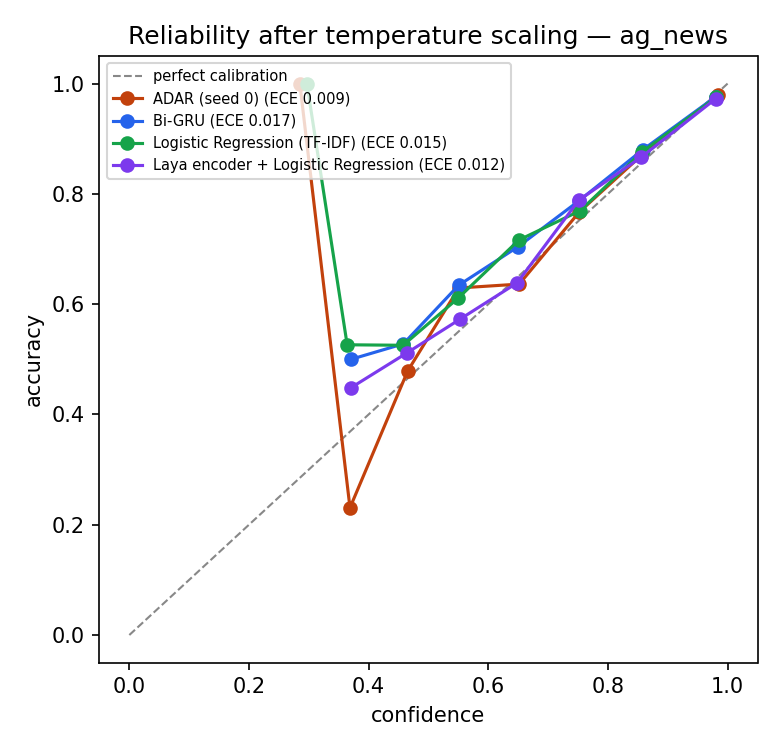

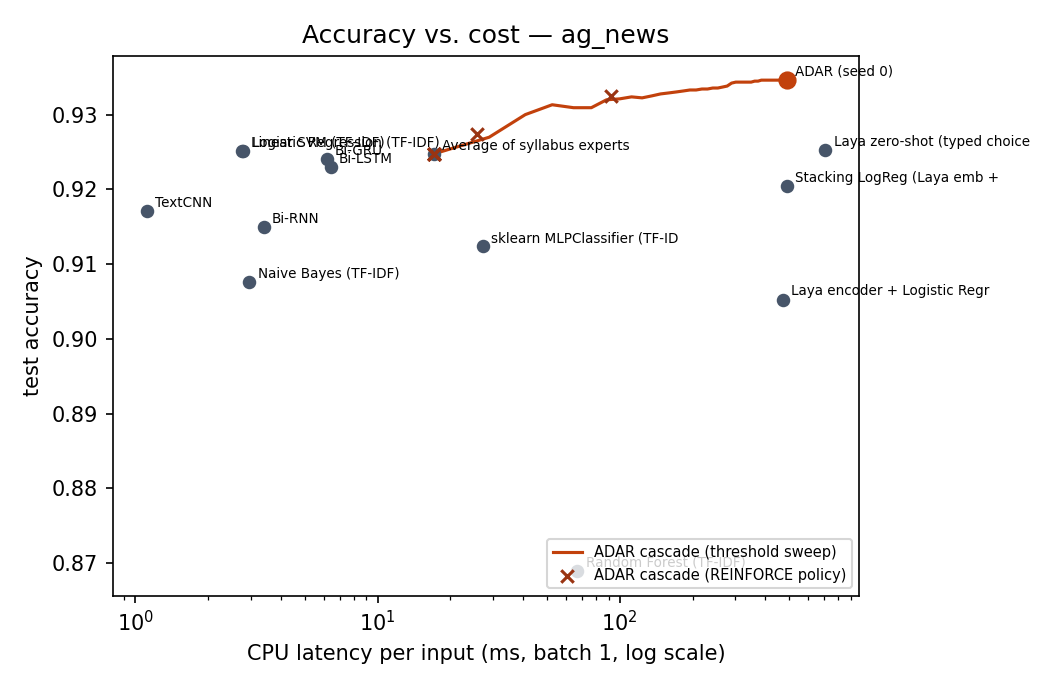

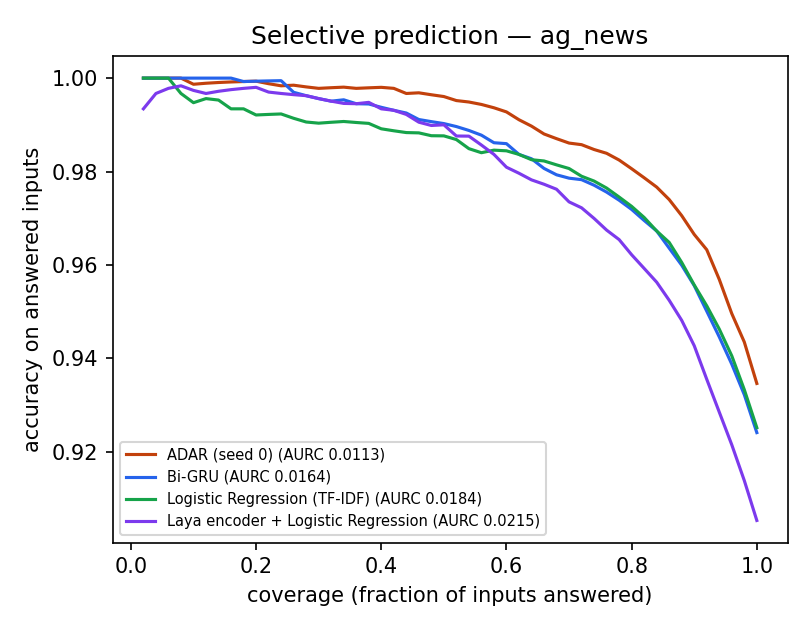

# ADAR results — emotion

emotion: train=16000 val=2000 test=2000 classes=6 folds=3

All probabilistic models are temperature-scaled on the validation split (ECE raw = before). CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.

| Model | Family | Syllabus unit | Accuracy | Macro-F1 | NLL | Brier | ECE (TS) | ECE (raw) | AURC | CPU ms/sample | Params |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Laya zero-shot (typed choice) | System One | III | 0.5805 | 0.4704 | 1.2109 | 0.5898 | 0.0877 | 0.2397 | 0.3082 | 653.23 | 394.78M |
| Laya encoder + Logistic Regression | System One + sklearn | III | 0.5915 | 0.5056 | 1.0845 | 0.5437 | 0.0321 | 0.2638 | 0.2514 | 375.44 | 394.78M |
| Naive Bayes (TF-IDF) | scikit-learn | - | 0.7605 | 0.6301 | 0.6771 | 0.3366 | 0.0251 | 0.0880 | 0.0828 | 1.27 | - |
| sklearn MLPClassifier (TF-IDF) | scikit-learn | - | 0.8460 | 0.7750 | 0.4251 | 0.2219 | 0.0268 | 0.0345 | 0.0411 | 5.45 | - |
| Random Forest (TF-IDF) | scikit-learn | - | 0.8650 | 0.8000 | 0.3596 | 0.1934 | 0.0136 | 0.2037 | 0.0346 | 56.97 | - |
| Logistic Regression (TF-IDF) | scikit-learn | - | 0.8675 | 0.8039 | 0.3562 | 0.1951 | 0.0307 | 0.0899 | 0.0304 | 1.81 | - |
| Stacking LogReg (Laya emb + experts) | Ensemble | I-III | 0.8795 | 0.8155 | 0.3430 | 0.1789 | 0.0177 | 0.0740 | 0.0294 | 384.63 | - |
| Linear SVM (TF-IDF) | scikit-learn | - | 0.8815 | 0.8222 | 0.2878 | 0.1611 | 0.0230 | 0.0523 | 0.0204 | 3.58 | - |
| TextCNN | Deep learning (syllabus) | I-II | 0.9055 | 0.8567 | 0.2149 | 0.1231 | 0.0153 | 0.0154 | 0.0122 | 1.06 | 1.15M |
| Bi-RNN | Deep learning (syllabus) | III | 0.9080 | 0.8619 | 0.2122 | 0.1194 | 0.0187 | 0.0302 | 0.0112 | 1.82 | 1.02M |
| Bi-GRU | Deep learning (syllabus) | III | 0.9220 | 0.8823 | 0.1740 | 0.1028 | 0.0184 | 0.0184 | 0.0081 | 3.02 | 1.15M |
| Average of syllabus experts | Ensemble | I-III | 0.9220 | 0.8810 | 0.1777 | 0.1052 | 0.0162 | 0.0200 | 0.0084 | 9.18 | 4.53M |
| Bi-LSTM | Deep learning (syllabus) | III | 0.9225 | 0.8816 | 0.1919 | 0.1100 | 0.0163 | 0.0168 | 0.0092 | 3.28 | 1.21M |
| ADAR ablation: laya only | Ablation | - | 0.6495 | 0.4771 | 0.9751 | 0.4860 | 0.0271 | 0.0197 | 0.1940 | 377.32 | 2.33M |
| **ADAR (ours, mean of 3 seeds)** | ADAR (ours) | I-IV | 0.9200 ± 0.0019 | 0.8790 ± 0.0054 | 0.1704 ± 0.0005 | 0.1014 ± 0.0005 | 0.0150 ± 0.0007 | 0.0181 | 0.0080 | 387.64 | 2.33M |
| ADAR ablation: experts only | Ablation | - | 0.9200 | 0.8802 | 0.1647 | 0.0970 | 0.0097 | 0.0124 | 0.0076 | 11.75 | 2.33M |
| ADAR ablation: no attention | Ablation | - | 0.9205 | 0.8732 | 0.1708 | 0.1004 | 0.0112 | 0.0139 | 0.0082 | 386.23 | 1.28M |
| **ADAR cascade (escalates 0%)** | ADAR (ours) | I-IV | 0.9220 | 0.8809 | 0.1777 | 0.1054 | 0.0162 | 0.0162 | 0.0084 | 9.56 | - |

## QC gates (paired bootstrap, 95% CI)

- PASS — ADAR accuracy > best scikit-learn model (Linear SVM (TF-IDF)): delta=+4.10pp, 95% CI [+2.90, +5.40]
- FAIL — ADAR accuracy > best syllabus deep model (Bi-LSTM): delta=+0.00pp, 95% CI [-0.75, +0.75]
- FAIL — ADAR accuracy > best expert ensemble (Average of syllabus experts): delta=+0.05pp, 95% CI [-0.75, +0.85]
- PASS — ADAR accuracy > best Laya zero-shot (Laya zero-shot (typed choice)): delta=+34.20pp, 95% CI [+31.80, +36.65]
- PASS — ADAR accuracy > best Laya linear probe (Laya encoder + Logistic Regression): delta=+33.10pp, 95% CI [+30.80, +35.35]
- PASS — ADAR accuracy > best stacking baseline (Stacking LogReg (Laya emb + experts)): delta=+4.30pp, 95% CI [+2.90, +5.65]
- PASS — ADAR NLL lower than every baseline (best: Bi-GRU): ADAR 0.1711 vs 0.1740
- PASS — ADAR BRIER lower than every baseline (best: Bi-GRU): ADAR 0.1018 vs 0.1028
- PASS — ADAR ECE (after TS) <= best baseline ECE + 0.005 (best: Random Forest (TF-IDF)): ADAR 0.0150 vs 0.0136
- PASS — full ADAR >= ADAR ablation: laya only (accuracy; NLL lower): delta=+27.30pp CI [+25.10, +29.60], NLL 0.1711 vs 0.9751
- FAIL — full ADAR >= ADAR ablation: experts only (accuracy; NLL lower): delta=+0.25pp CI [-0.65, +1.20], NLL 0.1711 vs 0.1647
- FAIL — full ADAR >= ADAR ablation: no attention (accuracy; NLL lower): delta=+0.20pp CI [-0.80, +1.20], NLL 0.1711 vs 0.1708
- PASS — ADAR stable across seeds (accuracy std < 0.5pp): std=0.19pp over 3 seeds
- PASS — Cascade keeps accuracy within 0.5pp of always-Laya while skipping Laya calls: acc 0.9220 vs 0.9225; Laya called on 0% of inputs; mean cost 9.6 vs 387.6 ms

## How ADAR routes between the syllabus experts (test set)

| Expert | mean routing weight α | predicted P(correct) | actual accuracy | AUC of P(correct) |
|---|---|---|---|---|
| TextCNN | 0.395 | 0.866 | 0.905 | 0.920 |
| Bi-RNN | 0.365 | 0.826 | 0.908 | 0.921 |
| Bi-LSTM | 0.403 | 0.848 | 0.922 | 0.906 |
| Bi-GRU | 0.435 | 0.871 | 0.922 | 0.912 |

## Cascade (cheap experts first, Laya + ADAR only when needed)

- tier-0 (experts) accuracy 0.9220 at 9.18 ms
- always escalate: accuracy 0.9225 at 387.6 ms
- chosen threshold (picked on validation): accuracy 0.9220, Laya called on 0.1% of inputs, mean 9.6 ms
- oracle router (upper bound): accuracy 0.9395 escalating 7.8%
- REINFORCE policy points: λ=0.05: acc 0.9230 @ 2% escalated; λ=0.1: acc 0.9305 @ 4% escalated; λ=0.2: acc 0.9220 @ 0% escalated; λ=0.4: acc 0.9220 @ 0% escalated; λ=0.8: acc 0.9220 @ 0% escalated; λ=1.6: acc 0.9220 @ 0% escalated



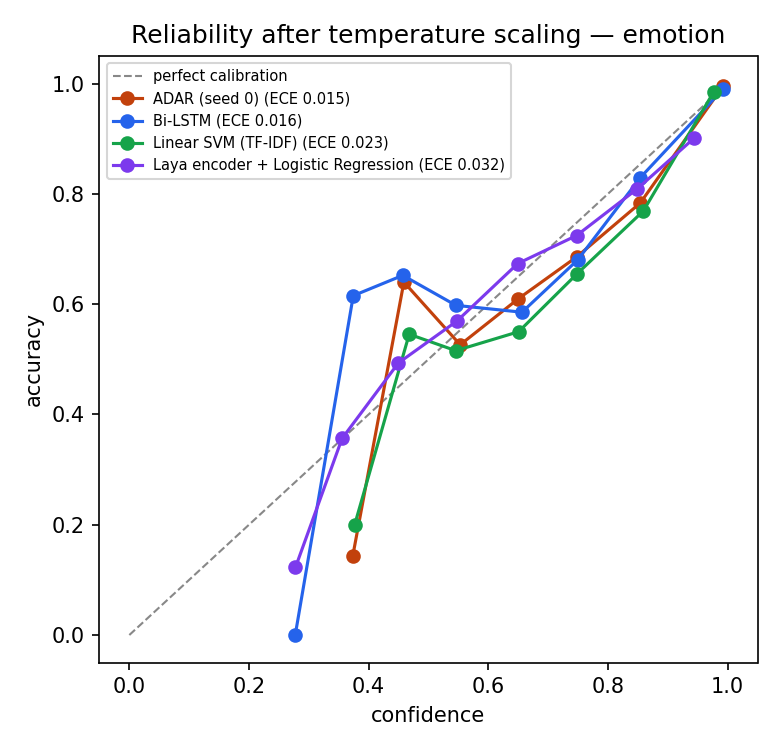

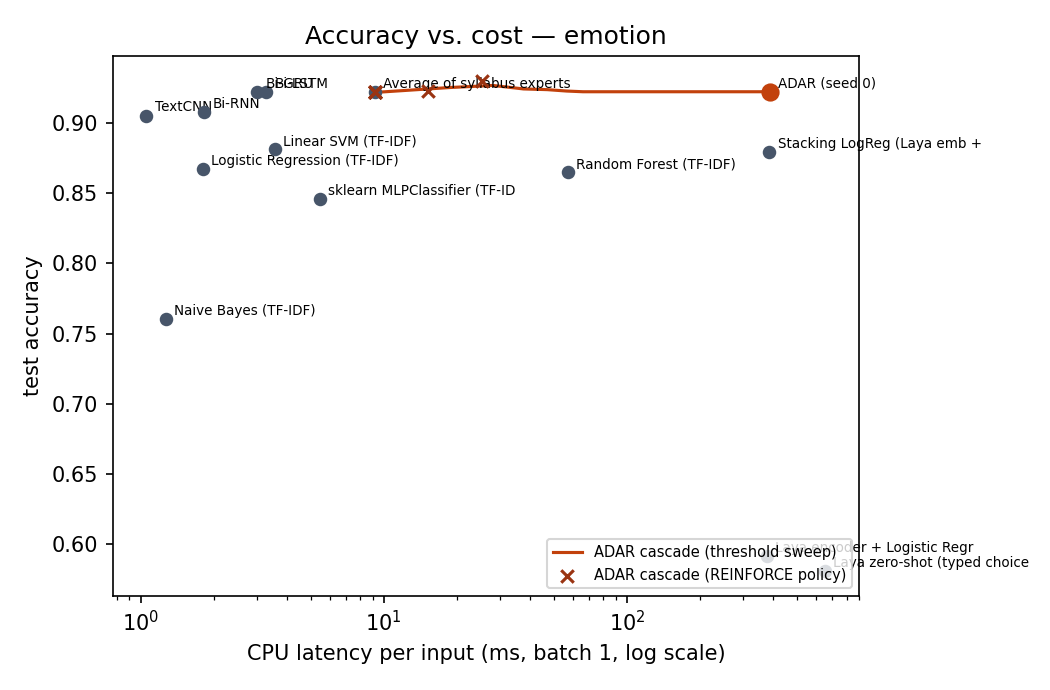

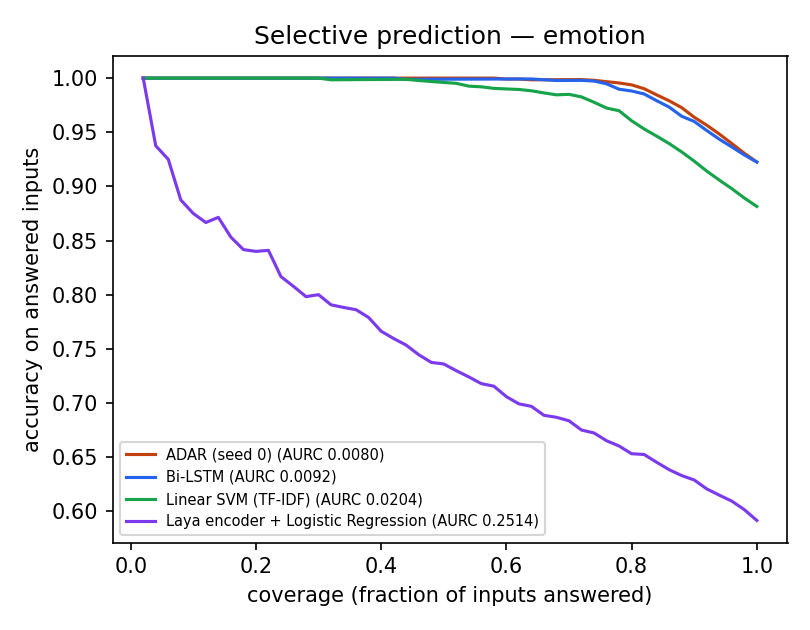

In [21]:
from IPython.display import Markdown, Image, display
for name in pipe.cfg["tasks"]:
    pipe.rs.run(f"report:{name}", pipe.stage_report, deps=[f"head:{name}"], force=True, name=name)
    rep = os.path.join(pipe.run_dir, "results", name, "REPORT.md")
    if os.path.exists(rep):
        display(Markdown(open(rep).read().split("![reliability]")[0]))
        for png in ("reliability.png", "accuracy_vs_latency.png", "risk_coverage.png"):
            display(Image(os.path.join(pipe.run_dir, "results", name, png)))

## 7. typed-decisions leaderboard (System One benchmark)
Evaluates the shipped Laya checkpoints on `LocalLLaMA/typed-decisions` and adds **ADAR-Cal**
(per question-type temperatures fitted on the *train* split only — test is never used for fitting or selection).

In [22]:
td = pipe.cfg["typed_decisions"]
if td["enabled"]:
    for m in td["models"]:
        print(m, pipe.rs.run(f"typed_decisions:{m}", pipe.stage_typed_decisions, model_id=m))

18:30:58 INFO [run ] typed_decisions:convaiinnovations/laya-typed-decisions


/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,

/usr/local/lib/python3.13/dist-packages/laya/agent.py:2157: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


18:31:14 INFO   typed-decisions train 100/1200 (8s)
18:31:23 INFO   typed-decisions train 200/1200 (17s)
18:31:32 INFO   typed-decisions train 300/1200 (26s)
18:31:50 INFO   typed-decisions train 400/1200 (44s)
18:32:07 INFO   typed-decisions train 500/1200 (61s)
18:32:24 INFO   typed-decisions train 600/1200 (78s)
18:32:40 INFO   typed-decisions train 700/1200 (94s)
18:32:57 INFO   typed-decisions train 800/1200 (111s)
18:33:14 INFO   typed-decisions train 900/1200 (128s)
18:33:29 INFO   typed-decisions train 1000/1200 (143s)
18:33:43 INFO   typed-decisions train 1100/1200 (157s)
18:33:57 INFO   typed-decisions train 1200/1200 (171s)
18:34:06 INFO   typed-decisions test 100/400 (9s)
18:34:23 INFO   typed-decisions test 200/400 (26s)
18:34:40 INFO   typed-decisions test 300/400 (42s)
18:34:54 INFO   typed-decisions test 400/400 (57s)
18:35:03 INFO typed-decisions convaiinnovations/laya-typed-decisions shipped test: {'decisions': 2000, 'accuracy': 0.7665, 'brier_soft': 0.061465647879173

## 8. Bundle: model cards, summary, zip (and optional Hugging Face upload)

In [23]:
print(pipe.rs.run("bundle", pipe.stage_bundle, force=True))
print(pipe.rs.summary())
display(Markdown(open(os.path.join(pipe.run_dir, "SUMMARY.md")).read()[:20000]))

18:39:03 INFO [run ] bundle
18:39:17 INFO bundle written: /kaggle/working/adar_outputs.zip (252.0 MB); proof bundle: /kaggle/working/adar_results_small.zip (0.9 MB)
18:39:17 INFO [done] bundle (13.1s)
{'zip': '/kaggle/working/adar_outputs.zip', 'proof_zip': '/kaggle/working/adar_results_small.zip', 'pushed': []}
       done  experts:ag_news  631.4
       done  sklearn:ag_news  573.0
       done  experts:emotion  95.3
       done  sklearn:emotion  331.3
       done  embed:ag_news  394.6
       done  probe:ag_news  323.5
       done  zeroshot:ag_news  163.1
       done  embed:emotion  44.6
       done  probe:emotion  144.3
       done  zeroshot:emotion  39.6
       done  head:ag_news  488.0
       done  router:ag_news  4.0
       done  head:emotion  38.5
       done  router:emotion  3.4
       done  report:ag_news  3.0
       done  report:emotion  1.7
       done  typed_decisions:convaiinnovations/laya-typed-decisions  245.3
       done  typed_decisions:convaiinnovations/laya  240.1
    

# ADAR run summary

# ADAR results — ag_news

ag_news: train=114000 val=6000 test=7600 classes=4 folds=3

All probabilistic models are temperature-scaled on the validation split (ECE raw = before). CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.

| Model | Family | Syllabus unit | Accuracy | Macro-F1 | NLL | Brier | ECE (TS) | ECE (raw) | AURC | CPU ms/sample | Params |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Random Forest (TF-IDF) | scikit-learn | - | 0.8689 | 0.8681 | 0.3842 | 0.1980 | 0.0137 | 0.2183 | 0.0382 | 66.89 | - |
| Laya encoder + Logistic Regression | System One + sklearn | III | 0.9053 | 0.9052 | 0.2778 | 0.1450 | 0.0123 | 0.0207 | 0.0215 | 472.15 | 394.78M |
| Naive Bayes (TF-IDF) | scikit-learn | - | 0.9076 | 0.9073 | 0.3011 | 0.1471 | 0.0259 | 0.0455 | 0.0285 | 2.95 | - |
| sklearn MLPClassifier (TF-IDF) | scikit-learn | - | 0.9124 | 0.9122 | 0.2750 | 0.1383 | 0.0178 | 0.0183 | 0.0232 | 27.24 | - |
| Bi-RNN | Deep learning (syllabus) | III | 0.9150 | 0.9149 | 0.2634 | 0.1333 | 0.0187 | 0.0178 | 0.0209 | 3.39 | 3.91M |
| TextCNN | Deep learning (syllabus) | I-II | 0.9171 | 0.9169 | 0.2580 | 0.1284 | 0.0192 | 0.0171 | 0.0210 | 1.11 | 4.04M |
| Stacking LogReg (Laya emb + experts) | Ensemble | I-III | 0.9204 | 0.9203 | 0.2323 | 0.1203 | 0.0091 | 0.0188 | 0.0154 | 489.21 | - |
| Bi-LSTM | Deep learning (syllabus) | III | 0.9230 | 0.9228 | 0.2324 | 0.1211 | 0.0140 | 0.0159 | 0.0157 | 6.40 | 4.11M |
| Bi-GRU | Deep learning (syllabus) | III | 0.9241 | 0.9239 | 0.2365 | 0.1218 | 0.0175 | 0.0179 | 0.0164 | 6.16 | 4.04M |
| Average of syllabus experts | Ensemble | I-III | 0.9247 | 0.9246 | 0.2349 | 0.1200 | 0.0164 | 0.0173 | 0.0166 | 17.06 | 16.09M |
| Logistic Regression (TF-IDF) | scikit-learn | - | 0.9251 | 0.9250 | 0.2410 | 0.1202 | 0.0149 | 0.0149 | 0.0184 | 2.79 | - |
| Linear SVM (TF-IDF) | scikit-learn | - | 0.9251 | 0.9250 | 0.2366 | 0.1179 | 0.0076 | 0.0228 | 0.0194 | 2.76 | - |
| Laya zero-shot (typed choice) | System One | III | 0.9253 | 0.9252 | 0.2366 | 0.1203 | 0.0214 | 0.0641 | 0.0167 | 706.27 | 394.78M |
| ADAR ablation: laya only | Ablation | - | 0.9182 | 0.9182 | 0.2380 | 0.1255 | 0.0084 | 0.0142 | 0.0158 | 473.92 | 2.33M |
| ADAR ablation: experts only | Ablation | - | 0.9263 | 0.9262 | 0.2266 | 0.1173 | 0.0119 | 0.0113 | 0.0152 | 19.40 | 2.33M |
| ADAR ablation: no attention | Ablation | - | 0.9320 | 0.9320 | 0.2020 | 0.1048 | 0.0091 | 0.0100 | 0.0120 | 490.80 | 1.28M |
| **ADAR (ours, mean of 3 seeds)** | ADAR (ours) | I-IV | 0.9328 ± 0.0016 | 0.9328 ± 0.0016 | 0.1973 ± 0.0030 | 0.1033 ± 0.0018 | 0.0092 ± 0.0008 | 0.0093 | 0.0115 | 491.73 | 2.33M |
| **ADAR cascade (escalates 36%)** | ADAR (ours) | I-IV | 0.9332 | 0.9332 | 0.2077 | 0.1057 | 0.0111 | 0.0111 | 0.0141 | 189.19 | - |

## QC gates (paired bootstrap, 95% CI)

- PASS — ADAR accuracy > best scikit-learn model (Logistic Regression (TF-IDF)): delta=+0.95pp, 95% CI [+0.47, +1.43]
- PASS — ADAR accuracy > best syllabus deep model (Bi-GRU): delta=+1.05pp, 95% CI [+0.63, +1.51]
- PASS — ADAR accuracy > best expert ensemble (Average of syllabus experts): delta=+0.99pp, 95% CI [+0.57, +1.42]
- PASS — ADAR accuracy > best Laya zero-shot (Laya zero-shot (typed choice)): delta=+0.93pp, 95% CI [+0.42, +1.47]
- PASS — ADAR accuracy > best Laya linear probe (Laya encoder + Logistic Regression): delta=+2.93pp, 95% CI [+2.43, +3.46]
- PASS — ADAR accuracy > best stacking baseline (Stacking LogReg (Laya emb + experts)): delta=+1.42pp, 95% CI [+1.00, +1.84]
- PASS — ADAR NLL lower than every baseline (best: Stacking LogReg (Laya emb + experts)): ADAR 0.1949 vs 0.2323
- PASS — ADAR BRIER lower than every baseline (best: Linear SVM (TF-IDF)): ADAR 0.1023 vs 0.1179
- PASS — ADAR ECE (after TS) <= best baseline ECE + 0.005 (best: Linear SVM (TF-IDF)): ADAR 0.0088 vs 0.0076
- PASS — full ADAR >= ADAR ablation: laya only (accuracy; NLL lower): delta=+1.64pp CI [+1.18, +2.12], NLL 0.1949 vs 0.2380
- PASS — full ADAR >= ADAR ablation: experts only (accuracy; NLL lower): delta=+0.83pp CI [+0.41, +1.28], NLL 0.1949 vs 0.2266
- PASS — full ADAR >= ADAR ablation: no attention (accuracy; NLL lower): delta=+0.26pp CI [+0.00, +0.57], NLL 0.1949 vs 0.2020
- PASS — ADAR stable across seeds (accuracy std < 0.5pp): std=0.16pp over 3 seeds
- PASS — Cascade keeps accuracy within 0.5pp of always-Laya while skipping Laya calls: acc 0.9332 vs 0.9346; Laya called on 36% of inputs; mean cost 189.2 vs 491.7 ms

## How ADAR routes between the syllabus experts (test set)

| Expert | mean routing weight α | predicted P(correct) | actual accuracy | AUC of P(correct) |
|---|---|---|---|---|
| TextCNN | 0.161 | 0.920 | 0.917 | 0.910 |
| Bi-RNN | 0.067 | 0.919 | 0.915 | 0.913 |
| Bi-LSTM | 0.150 | 0.925 | 0.923 | 0.900 |
| Bi-GRU | 0.160 | 0.925 | 0.924 | 0.899 |

## Cascade (cheap experts first, Laya + ADAR only when needed)

- tier-0 (experts) accuracy 0.9247 at 17.06 ms
- always escalate: accuracy 0.9346 at 491.7 ms
- chosen threshold (picked on validation): accuracy 0.9332, Laya called on 36.3% of inputs, mean 189.2 ms
- oracle router (upper bound): accuracy 0.9487 escalating 7.5%
- REINFORCE policy points: λ=0.05: acc 0.9325 @ 16% escalated; λ=0.1: acc 0.9274 @ 2% escalated; λ=0.2: acc 0.9247 @ 0% escalated; λ=0.4: acc 0.9247 @ 0% escalated; λ=0.8: acc 0.9247 @ 0% escalated; λ=1.6: acc 0.9247 @ 0% escalated

![reliability](reliability.png) ![accuracy vs latency](accuracy_vs_latency.png) ![risk coverage](risk_coverage.png)


# ADAR results — emotion

emotion: train=16000 val=2000 test=2000 classes=6 folds=3

All probabilistic models are temperature-scaled on the validation split (ECE raw = before). CPU latency = median batch-1 time on the run's CPU. Test rows are identical for every model.

| Model | Family | Syllabus unit | Accuracy | Macro-F1 | NLL | Brier | ECE (TS) | ECE (raw) | AURC | CPU ms/sample | Params |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Laya zero-shot (typed choice) | System One | III | 0.5805 | 0.4704 | 1.2109 | 0.5898 | 0.0877 | 0.2397 | 0.3082 | 653.23 | 394.78M |
| Laya encoder + Logistic Regression | System One + sklearn | III | 0.5915 | 0.5056 | 1.0845 | 0.5437 | 0.0321 | 0.2638 | 0.2514 | 375.44 | 394.78M |
| Naive Bayes (TF-IDF) | scikit-learn | - | 0.7605 | 0.6301 | 0.6771 | 0.3366 | 0.0251 | 0.0880 | 0.0828 | 1.27 | - |
| sklearn MLPClassifier (TF-IDF) | scikit-learn | - | 0.8460 | 0.7750 | 0.4251 | 0.2219 | 0.0268 | 0.0345 | 0.0411 | 5.45 | - |
| Random Forest (TF-IDF) | scikit-learn | - | 0.8650 | 0.8000 | 0.3596 | 0.1934 | 0.0136 | 0.2037 | 0.0346 | 56.97 | - |
| Logistic Regression (TF-IDF) | scikit-learn | - | 0.8675 | 0.8039 | 0.3562 | 0.1951 | 0.0307 | 0.0899 | 0.0304 | 1.81 | - |
| Stacking LogReg (Laya emb + experts) | Ensemble | I-III | 0.8795 | 0.8155 | 0.3430 | 0.1789 | 0.0177 | 0.0740 | 0.0294 | 384.63 | - |
| Linear SVM (TF-IDF) | scikit-learn | - | 0.8815 | 0.8222 | 0.2878 | 0.1611 | 0.0230 | 0.0523 | 0.0204 | 3.58 | - |
| TextCNN | Deep learning (syllabus) | I-II | 0.9055 | 0.8567 | 0.2149 | 0.1231 | 0.0153 | 0.0154 | 0.0122 | 1.06 | 1.15M |
| Bi-RNN | Deep learning (syllabus) | III | 0.9080 | 0.8619 | 0.2122 | 0.1194 | 0.0187 | 0.0302 | 0.0112 | 1.82 | 1.02M |
| Bi-GRU | Deep learning (syllabus) | III | 0.9220 | 0.8823 | 0.1740 | 0.1028 | 0.0184 | 0.0184 | 0.0081 | 3.02 | 1.15M |
| Average of syllabus experts | Ensemble | I-III | 0.9220 | 0.8810 | 0.1777 | 0.1052 | 0.0162 | 0.0200 | 0.0084 | 9.18 | 4.53M |
| Bi-LSTM | Deep learning (syllabus) | III | 0.9225 | 0.8816 | 0.1919 | 0.1100 | 0.0163 | 0.0168 | 0.0092 | 3.28 | 1.21M |
| ADAR ablation: laya only | Ablation | - | 0.6495 | 0.4771 | 0.9751 | 0.4860 | 0.0271 | 0.0197 | 0.1940 | 377.32 | 2.33M |
| **ADAR (ours, mean of 3 seeds)** | ADAR (ours) | I-IV | 0.9200 ± 0.0019 | 0.8790 ± 0.0054 | 0.1704 ± 0.0005 | 0.1014 ± 0.0005 | 0.0150 ± 0.0007 | 0.0181 | 0.0080 | 387.64 | 2.33M |
| ADAR ablation: experts only | Ablation | - | 0.9200 | 0.8802 | 0.1647 | 0.0970 | 0.0097 | 0.0124 | 0.0076 | 11.75 | 2.33M |
| ADAR ablation: no attention | Ablation | - | 0.9205 | 0.8732 | 0.1708 | 0.1004 | 0.0112 | 0.0139 | 0.0082 | 386.23 | 1.28M |
| **ADAR cascade (escalates 0%)** | ADAR (ours) | I-IV | 0.9220 | 0.8809 | 0.1777 | 0.1054 | 0.0162 | 0.0162 | 0.0084 | 9.56 | - |

## QC gates (paired bootstrap, 95% CI)

- PASS — ADAR accuracy > best scikit-learn model (Linear SVM (TF-IDF)): delta=+4.10pp, 95% CI [+2.90, +5.40]
- FAIL — ADAR accuracy > best syllabus deep model (Bi-LSTM): delta=+0.00pp, 95% CI [-0.75, +0.75]
- FAIL — ADAR accuracy > best expert ensemble (Average of syllabus experts): delta=+0.05pp, 95% CI [-0.75, +0.85]
- PASS — ADAR accuracy > best Laya zero-shot (Laya zero-shot (typed choice)): delta=+34.20pp, 95% CI [+31.80, +36.65]
- PASS — ADAR accuracy > best Laya linear probe (Laya encoder + Logistic Regression): delta=+33.10pp, 95% CI [+30.80, +35.35]
- PASS — ADAR accuracy > best stacking baseline (Stacking LogReg (Laya emb + experts)): delta=+4.30pp, 95% CI [+2.90, +5.65]
- PASS — ADAR NLL lower than every baseline (best: Bi-GRU): ADAR 0.1711 vs 0.1740
- PASS — ADAR BRIER lower than every baseline (best: Bi-GRU): ADAR 0.1018 vs 0.1028
- PASS — ADAR ECE (after TS) <= best baseline ECE + 0.005 (best: Random Forest (TF-IDF)): ADAR 0.0150 vs 0.0136
- PASS — full ADAR >= ADAR ablation: laya only (accuracy; NLL lower): delta=+27.30pp CI [+25.10, +29.60], NLL 0.1711 vs 0.9751
- FAIL — full ADAR >= ADAR ablation: experts only (accuracy; NLL lower): delta=+0.25pp CI [-0.65, +1.20], NLL 0.1711 vs 0.1647
- FAIL — full ADAR >= ADAR ablation: no attention (accuracy; NLL lower): delta=+0.20pp CI [-0.80, +1.20], NLL 0.1711 vs 0.1708
- PASS — ADAR stable across seeds (accuracy std < 0.5pp): std=0.19pp over 3 seeds
- PASS — Cascade keeps accuracy within 0.5pp of always-Laya while skipping Laya calls: acc 0.9220 vs 0.9225; Laya called on 0% of inputs; mean cost 9.6 vs 387.6 ms

## How ADAR routes between the syllabus experts (test set)

| Expert | mean routing weight α | predicted P(correct) | actual accuracy | AUC of P(correct) |
|---|---|---|---|---|
| TextCNN | 0.395 | 0.866 | 0.905 | 0.920 |
| Bi-RNN | 0.365 | 0.826 | 0.908 | 0.921 |
| Bi-LSTM | 0.403 | 0.848 | 0.922 | 0.906 |
| Bi-GRU | 0.435 | 0.871 | 0.922 | 0.912 |

## Cascade (cheap experts first, Laya + ADAR only when needed)

- tier-0 (experts) accuracy 0.9220 at 9.18 ms
- always escalate: accuracy 0.9225 at 387.6 ms
- chosen threshold (picked on validation): accuracy 0.9220, Laya called on 0.1% of inputs, mean 9.6 ms
- oracle router (upper bound): accuracy 0.9395 escalating 7.8%
- REINFORCE policy points: λ=0.05: acc 0.9230 @ 2% escalated; λ=0.1: acc 0.9305 @ 4% escalated; λ=0.2: acc 0.9220 @ 0% escalated; λ=0.4: acc 0.9220 @ 0% escalated; λ=0.8: acc 0.9220 @ 0% escalated; λ=1.6: acc 0.9220 @ 0% escalated

![reliability](reliability.png) ![accuracy vs latency](accuracy_vs_latency.png) ![risk coverage](risk_coverage.png)


## typed-decisions — convaiinnovations/laya-typed-decisions

| Variant | Accuracy | Brier (soft gold) | Brier (one-hot) | ECE (10 bins) | KL |
|---|---|---|---|---|---|
| as shipped | 0.7665 | 0.0615 | 0.4009 | 0.2137 | 0.1170 |
| + ADAR-Cal (hard, fitted on train) | 0.7665 | 0.1476 | 0.3276 | 0.0626 | 0.5264 |

p50 latency 148.3 ms per case (5 questions) on this GPU.

## typed-decisions — convaiinnovations/laya

| Variant | Accuracy | Brier (soft gold) | Brier (one-hot) | ECE (10 bins) | KL |
|---|---|---|---|---|---|
| as shipped | 0.3630 | 0.3154 | 0.7509 | 0.1731 | 0.5687 |
| + ADAR-Cal (soft, fitted on train) | 0.3630 | 0.2365 | 0.6783 | 0.0214 | 0.4325 |

p50 latency 147.8 ms per case (5 questions) on this GPU.

## Stage status

```
       done  experts:ag_news
       done  sklearn:ag_news
       done  experts:emotion
       done  sklearn:emotion
       done  embed:ag_news
       done  probe:ag_news
       done  zeroshot:ag_news
       done  embed:emotion
       done  probe:emotion
       done  zeroshot:emotion
       done  head:ag_news
       done  router:ag_news
       done  head:emotion
       done  router:emotion
       done  report:ag_news
       done  report:emotion
       done  typed_decisions:convaiinnovations/laya-typed-decisions
       done  typed_decisions:convaiinnovations/laya
    running  bundle
```


## 9. Try the published head
Loads `adar_run/publish/adar-head-ag_news` exactly as someone downloading it would.

In [24]:
from adar.inference import ADARClassifier
pub = os.path.join(pipe.run_dir, "publish", f"adar-head-{pipe.cfg['tasks'][0]}")
if os.path.isdir(pub):
    clf = ADARClassifier.from_pretrained(pub)
    for r in clf.predict(["NASA's new telescope captured images of a distant galaxy cluster.",
                          "Real Madrid beat Barcelona 3-1 in the Champions League semi-final on Tuesday."]):
        print(r)

{'label': 'sci_tech', 'probabilities': {'world': 0.0726, 'sports': 0.0001, 'business': 0.0006, 'sci_tech': 0.9267}, 'p_head_correct': 0.9664, 'escalate': False, 'p_expert_correct': {'textcnn': 0.9652, 'rnn': 0.9711, 'lstm': 0.9716, 'gru': 0.9696}, 'routing_weights': {'textcnn': 0.0455, 'rnn': 0.0352, 'lstm': 0.053, 'gru': 0.0693}}
{'label': 'sports', 'probabilities': {'world': 0.0103, 'sports': 0.9897, 'business': 0.0, 'sci_tech': 0.0}, 'p_head_correct': 0.9975, 'escalate': False, 'p_expert_correct': {'textcnn': 0.9982, 'rnn': 0.9983, 'lstm': 0.9984, 'gru': 0.9984}, 'routing_weights': {'textcnn': 0.1008, 'rnn': 0.0335, 'lstm': 0.1398, 'gru': 0.1452}}
